In [2]:
# =============================================================
# CELL 1: Imports and Setup
# =============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from matplotlib.patches import Patch
import warnings

warnings.filterwarnings('ignore')

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Custom color palettes
PHASE_COLORS = {
    'menstrual': '#e74c3c',
    'follicular': '#2ecc71',
    'ovulatory': '#f39c12',
    'luteal': '#9b59b6'
}

DIFFICULTY_COLORS = {
    'normal': '#27ae60',
    'ambiguous': '#f1c40f',
    'conflicting': '#e67e22',
    'elevated_risk': '#c0392b'
}

PROFILE_COLORS = {
    'minimal_tracker': '#3498db',
    'app_logger': '#1abc9c',
    'basic_wearable': '#9b59b6',
    'advanced_wearable': '#e74c3c',
    'inconsistent_user': '#95a5a6'
}

print("✓ Libraries loaded and styling configured")

✓ Libraries loaded and styling configured


In [6]:
# Display dataset metadata (robust to missing keys)
print("=" * 60)
print("DATASET METADATA")
print("=" * 60)
print(f"Total samples: {metadata.get('total_samples', 'N/A')}")
print(f"Generation date: {metadata.get('generation_date', 'N/A')}")
print(f"\nDifficulty distribution: {metadata.get('difficulty_distribution', 'N/A')}")
print(f"Profile distribution: {metadata.get('profile_distribution', 'N/A')}")

print(f"\nInvariant validation:")
invariant = metadata.get('invariant_validation', {})
if invariant:
    for k, v in invariant.items():
        print(f"  {k}: {v}")
else:
    print("  N/A")


DATASET METADATA
Total samples: 500
Generation date: 2026-06-23T11:40:10.966565+00:00

Difficulty distribution: N/A
Profile distribution: {'minimal_tracker': 75, 'app_logger': 100, 'basic_wearable': 125, 'advanced_wearable': 125, 'inconsistent_user': 75}

Invariant validation:
  N/A


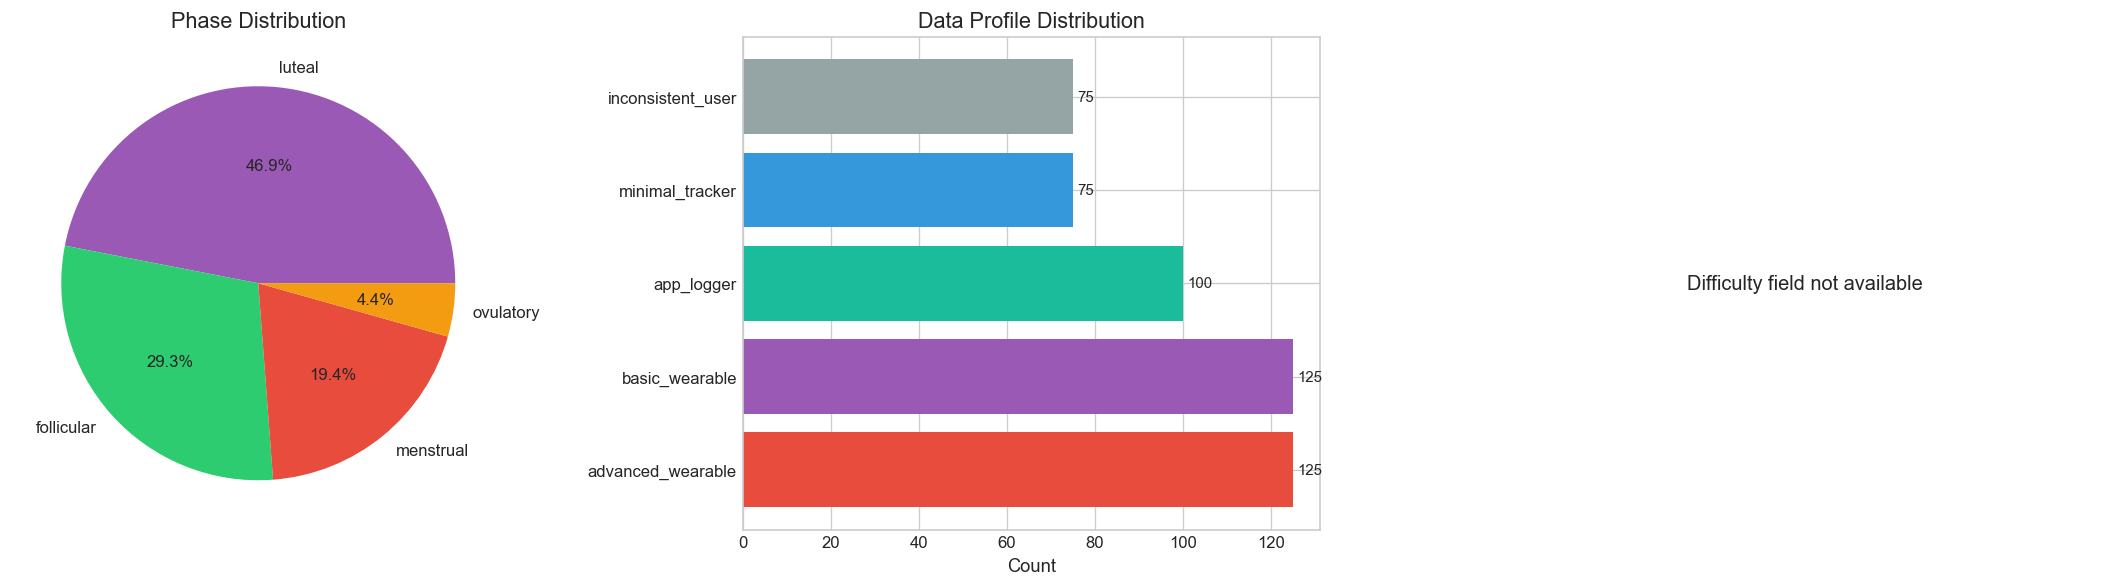

In [11]:
# Plot core distributions (robust to missing fields)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Phase distribution (pie)
phase_counts = df['phase'].value_counts()
axes[0].pie(phase_counts.values, labels=phase_counts.index, autopct='%1.1f%%', colors=[PHASE_COLORS.get(p, '#999') for p in phase_counts.index])
axes[0].set_title('Phase Distribution')

# Data profile distribution (barh)
profile_counts = df['data_profile'].value_counts()
axes[1].barh(profile_counts.index, profile_counts.values, color=[PROFILE_COLORS.get(p, '#777') for p in profile_counts.index])
axes[1].set_title('Data Profile Distribution')
axes[1].set_xlabel('Count')
for i, val in enumerate(profile_counts.values):
    axes[1].text(val + 1, i, str(val), va='center', fontsize=9)

# Difficulty distribution (optional)
if 'difficulty' in df.columns and not df['difficulty'].isnull().all():
    diff_counts = df['difficulty'].value_counts()
    colors_diff = [DIFFICULTY_COLORS.get(d, '#999') for d in diff_counts.index]
    axes[2].bar(diff_counts.index, diff_counts.values, color=colors_diff, edgecolor='white', width=0.6)
    axes[2].set_ylabel('Count')
    axes[2].set_title('Difficulty Distribution')
    for bar, val in zip(axes[2].containers[0], diff_counts.values):
        axes[2].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, str(val), ha='center', fontsize=9)
else:
    axes[2].axis('off')
    axes[2].text(0.5, 0.5, 'Difficulty field not available', ha='center', va='center', fontsize=12)

plt.tight_layout()
plt.show()


KeyError: 'difficulty'

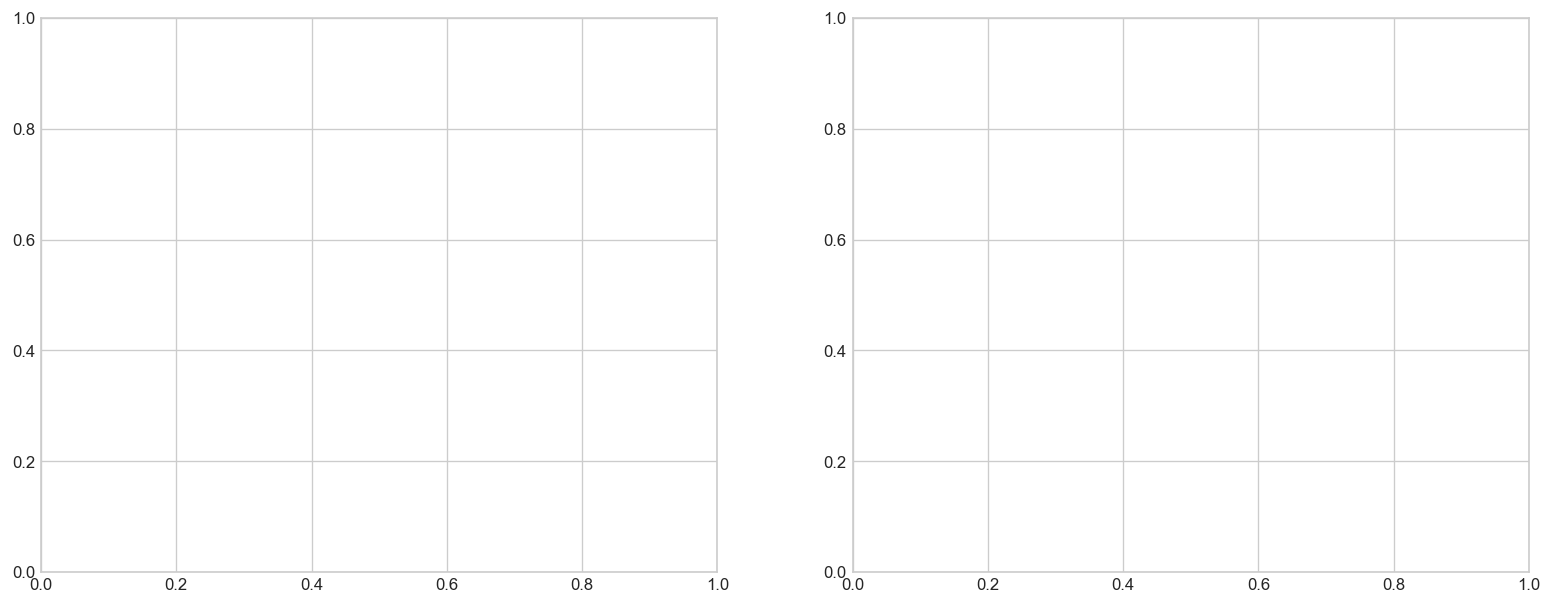

In [12]:
# =============================================================
# CELL 4: Phase Distribution by Difficulty and Profile (Stacked)
# =============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Phase by Difficulty
ct1 = pd.crosstab(df['difficulty'], df['phase'])
ct1 = ct1[['menstrual', 'follicular', 'ovulatory', 'luteal']]
ct1.plot(kind='bar', stacked=True, ax=axes[0],
         color=[PHASE_COLORS[p] for p in ct1.columns], edgecolor='white', width=0.7)
axes[0].set_title('Phase Distribution by Difficulty Level', fontweight='bold')
axes[0].set_xlabel('Difficulty')
axes[0].set_ylabel('Count')
axes[0].legend(title='Phase', bbox_to_anchor=(1.0, 1.0))
axes[0].tick_params(axis='x', rotation=0)

# Phase by Profile
ct2 = pd.crosstab(df['data_profile'], df['phase'])
ct2 = ct2[['menstrual', 'follicular', 'ovulatory', 'luteal']]
ct2.plot(kind='bar', stacked=True, ax=axes[1],
         color=[PHASE_COLORS[p] for p in ct2.columns], edgecolor='white', width=0.7)
axes[1].set_title('Phase Distribution by Data Profile', fontweight='bold')
axes[1].set_xlabel('Data Profile')
axes[1].set_ylabel('Count')
axes[1].legend(title='Phase', bbox_to_anchor=(1.0, 1.0))
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('viz_02_phase_by_category.png', bbox_inches='tight')
plt.show()

In [13]:
# =============================================================
# CELL 5: Resting Heart Rate Analysis
# =============================================================

df_hr = df[df['resting_hr'].notna()].copy()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Box plot by phase
sns.boxplot(data=df_hr, x='phase', y='resting_hr', ax=axes[0, 0],
            order=['menstrual', 'follicular', 'ovulatory', 'luteal'],
            palette=PHASE_COLORS, width=0.6)
axes[0, 0].set_title('Resting HR by Cycle Phase', fontweight='bold')
axes[0, 0].set_ylabel('Resting HR (bpm)')
axes[0, 0].set_xlabel('')

# Add reference ranges
ref_ranges = {'menstrual': (58, 72), 'follicular': (55, 68),
              'ovulatory': (60, 75), 'luteal': (65, 85)}
for i, phase in enumerate(['menstrual', 'follicular', 'ovulatory', 'luteal']):
    lo, hi = ref_ranges[phase]
    axes[0, 0].hlines([lo, hi], i - 0.3, i + 0.3, colors='red',
                      linestyles='dashed', linewidth=0.8, alpha=0.7)

# Violin plot by difficulty
sns.violinplot(data=df_hr, x='difficulty', y='resting_hr', ax=axes[0, 1],
               palette=DIFFICULTY_COLORS, inner='quartile', width=0.8)
axes[0, 1].set_title('Resting HR by Difficulty Level', fontweight='bold')
axes[0, 1].set_ylabel('Resting HR (bpm)')
axes[0, 1].set_xlabel('')
axes[0, 1].tick_params(axis='x', rotation=10)

# HR distribution histogram by phase
for phase in ['menstrual', 'follicular', 'ovulatory', 'luteal']:
    subset = df_hr[df_hr['phase'] == phase]['resting_hr']
    axes[1, 0].hist(subset, bins=15, alpha=0.5, label=phase,
                    color=PHASE_COLORS[phase], edgecolor='white')
axes[1, 0].set_title('Resting HR Distribution by Phase', fontweight='bold')
axes[1, 0].set_xlabel('Resting HR (bpm)')
axes[1, 0].set_ylabel('Count')
axes[1, 0].legend()

# Strip plot by phase and difficulty
sns.stripplot(data=df_hr, x='phase', y='resting_hr', hue='difficulty',
              ax=axes[1, 1], order=['menstrual', 'follicular', 'ovulatory', 'luteal'],
              palette=DIFFICULTY_COLORS, alpha=0.6, size=4, jitter=0.3)
axes[1, 1].set_title('Resting HR: Phase × Difficulty', fontweight='bold')
axes[1, 1].set_ylabel('Resting HR (bpm)')
axes[1, 1].set_xlabel('')
axes[1, 1].legend(title='Difficulty', bbox_to_anchor=(1.05, 1), fontsize=8)

plt.tight_layout()
plt.savefig('viz_03_resting_hr_analysis.png', bbox_inches='tight')
plt.show()

print(f"\nSamples with HR data: {len(df_hr)} / {len(df)}")
print(f"\nMean HR by phase:")
print(df_hr.groupby('phase')['resting_hr'].agg(['mean', 'std', 'min', 'max']).round(2))

KeyError: 'resting_hr'

In [14]:
# =============================================================
# CELL 6: Sleep Analysis
# =============================================================

df_sleep = df[df['sleep_hours'].notna()].copy()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Sleep hours by phase
sns.boxplot(data=df_sleep, x='phase', y='sleep_hours', ax=axes[0, 0],
            order=['menstrual', 'follicular', 'ovulatory', 'luteal'],
            palette=PHASE_COLORS, width=0.6)
axes[0, 0].set_title('Sleep Hours by Cycle Phase', fontweight='bold')
axes[0, 0].set_ylabel('Sleep Hours')
axes[0, 0].axhline(y=7.0, color='gray', linestyle='--', alpha=0.5, label='7h reference')
axes[0, 0].legend()

# Sleep quality distribution by phase
df_sq = df[df['sleep_quality'].notna()]
ct_sq = pd.crosstab(df_sq['phase'], df_sq['sleep_quality'], normalize='index')
ct_sq = ct_sq[['poor', 'moderate', 'good']]
ct_sq.plot(kind='bar', stacked=True, ax=axes[0, 1],
           color=['#e74c3c', '#f39c12', '#27ae60'], edgecolor='white', width=0.7)
axes[0, 1].set_title('Sleep Quality Proportion by Phase', fontweight='bold')
axes[0, 1].set_ylabel('Proportion')
axes[0, 1].set_xlabel('')
axes[0, 1].legend(title='Quality')
axes[0, 1].tick_params(axis='x', rotation=0)

# Sleep hours by difficulty
sns.violinplot(data=df_sleep, x='difficulty', y='sleep_hours', ax=axes[1, 0],
               palette=DIFFICULTY_COLORS, inner='box', width=0.8)
axes[1, 0].set_title('Sleep Hours by Difficulty', fontweight='bold')
axes[1, 0].set_ylabel('Sleep Hours')
axes[1, 0].tick_params(axis='x', rotation=10)

# Sleep hours vs resting HR (scatter)
df_both = df[(df['sleep_hours'].notna()) & (df['resting_hr'].notna())].copy()
for phase in ['menstrual', 'follicular', 'ovulatory', 'luteal']:
    subset = df_both[df_both['phase'] == phase]
    axes[1, 1].scatter(subset['sleep_hours'], subset['resting_hr'],
                       color=PHASE_COLORS[phase], alpha=0.5, s=30, label=phase)
axes[1, 1].set_title('Sleep Hours vs Resting HR', fontweight='bold')
axes[1, 1].set_xlabel('Sleep Hours')
axes[1, 1].set_ylabel('Resting HR (bpm)')
axes[1, 1].legend(title='Phase')

plt.tight_layout()
plt.savefig('viz_04_sleep_analysis.png', bbox_inches='tight')
plt.show()

print(f"\nSamples with sleep data: {len(df_sleep)} / {len(df)}")
print(f"\nMean sleep hours by phase:")
print(df_sleep.groupby('phase')['sleep_hours'].agg(['mean', 'std']).round(2))

KeyError: 'sleep_hours'

KeyError: 'difficulty'

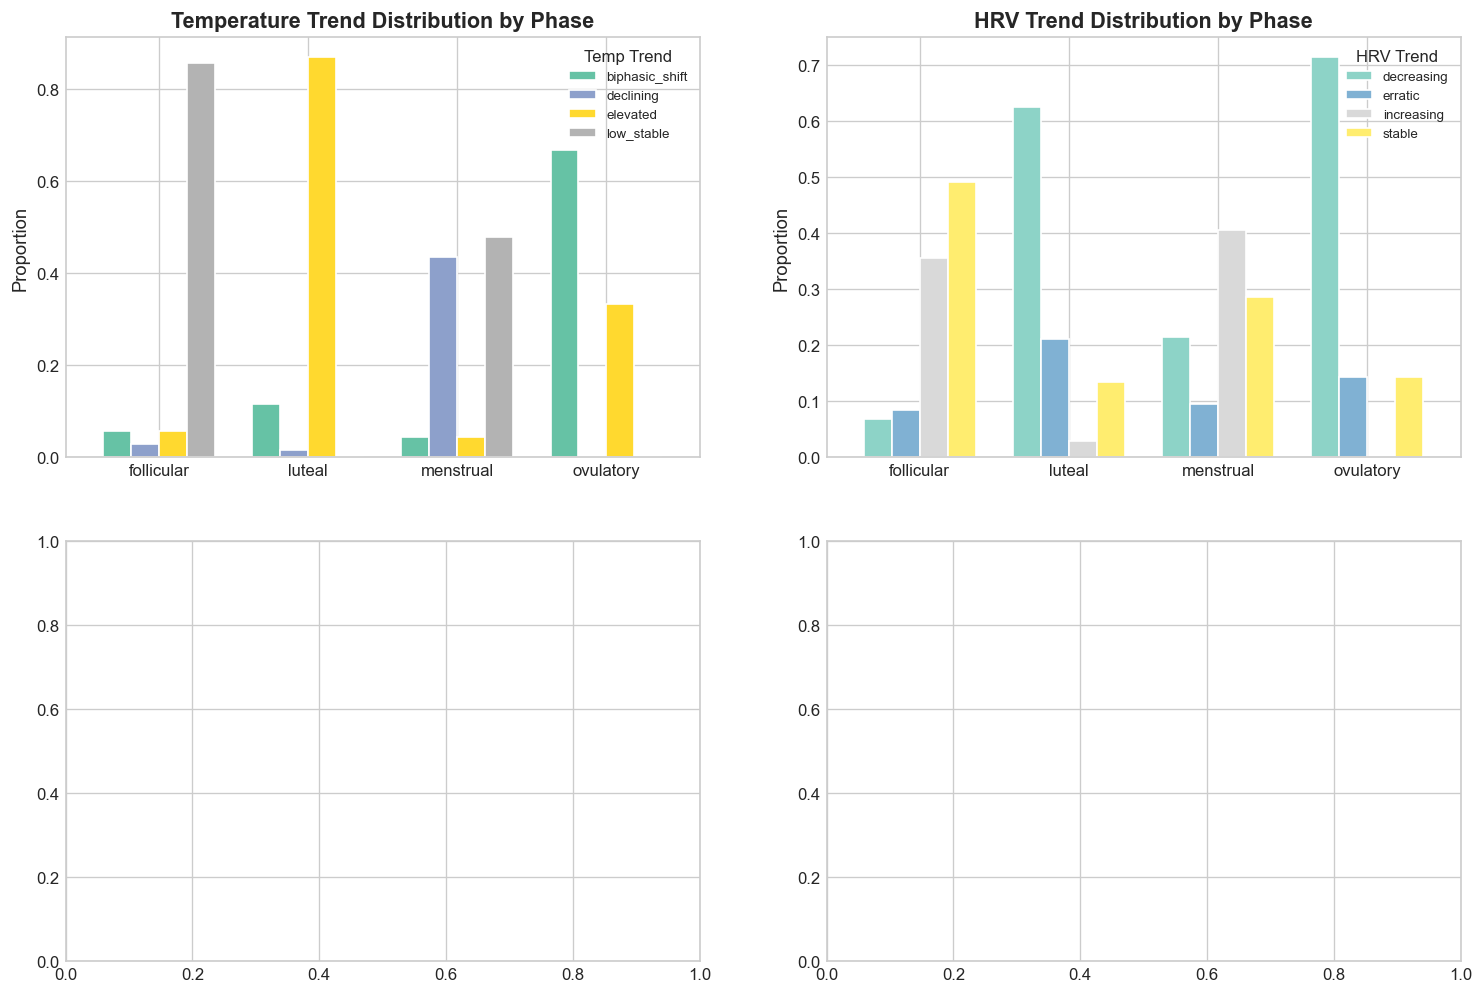

In [15]:
# =============================================================
# CELL 7: Temperature Trend and HRV Trend Analysis
# =============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Temperature trend by phase
df_temp = df[df['temperature_trend'].notna()]
ct_temp = pd.crosstab(df_temp['phase'], df_temp['temperature_trend'], normalize='index')
ct_temp.plot(kind='bar', ax=axes[0, 0], width=0.75, edgecolor='white',
             colormap='Set2')
axes[0, 0].set_title('Temperature Trend Distribution by Phase', fontweight='bold')
axes[0, 0].set_ylabel('Proportion')
axes[0, 0].set_xlabel('')
axes[0, 0].legend(title='Temp Trend', fontsize=8, bbox_to_anchor=(1.0, 1.0))
axes[0, 0].tick_params(axis='x', rotation=0)

# HRV trend by phase
df_hrv = df[df['hrv_trend'].notna()]
ct_hrv = pd.crosstab(df_hrv['phase'], df_hrv['hrv_trend'], normalize='index')
ct_hrv.plot(kind='bar', ax=axes[0, 1], width=0.75, edgecolor='white',
            colormap='Set3')
axes[0, 1].set_title('HRV Trend Distribution by Phase', fontweight='bold')
axes[0, 1].set_ylabel('Proportion')
axes[0, 1].set_xlabel('')
axes[0, 1].legend(title='HRV Trend', fontsize=8, bbox_to_anchor=(1.0, 1.0))
axes[0, 1].tick_params(axis='x', rotation=0)

# Temperature trend by difficulty (heatmap)
df_temp_d = df[df['temperature_trend'].notna()]
ct_td = pd.crosstab(df_temp_d['difficulty'], df_temp_d['temperature_trend'])
sns.heatmap(ct_td, annot=True, fmt='d', cmap='YlOrRd', ax=axes[1, 0],
            linewidths=0.5, cbar_kws={'label': 'Count'})
axes[1, 0].set_title('Temperature Trend × Difficulty (Count)', fontweight='bold')
axes[1, 0].set_xlabel('Temperature Trend')
axes[1, 0].set_ylabel('Difficulty')

# HRV trend by difficulty (heatmap)
ct_hd = pd.crosstab(df_hrv['difficulty'], df_hrv['hrv_trend'])
sns.heatmap(ct_hd, annot=True, fmt='d', cmap='YlGnBu', ax=axes[1, 1],
            linewidths=0.5, cbar_kws={'label': 'Count'})
axes[1, 1].set_title('HRV Trend × Difficulty (Count)', fontweight='bold')
axes[1, 1].set_xlabel('HRV Trend')
axes[1, 1].set_ylabel('Difficulty')

plt.tight_layout()
plt.savefig('viz_05_trends_analysis.png', bbox_inches='tight')
plt.show()

print(f"Samples with temp data: {len(df_temp)}")
print(f"Samples with HRV data: {len(df_hrv)}")

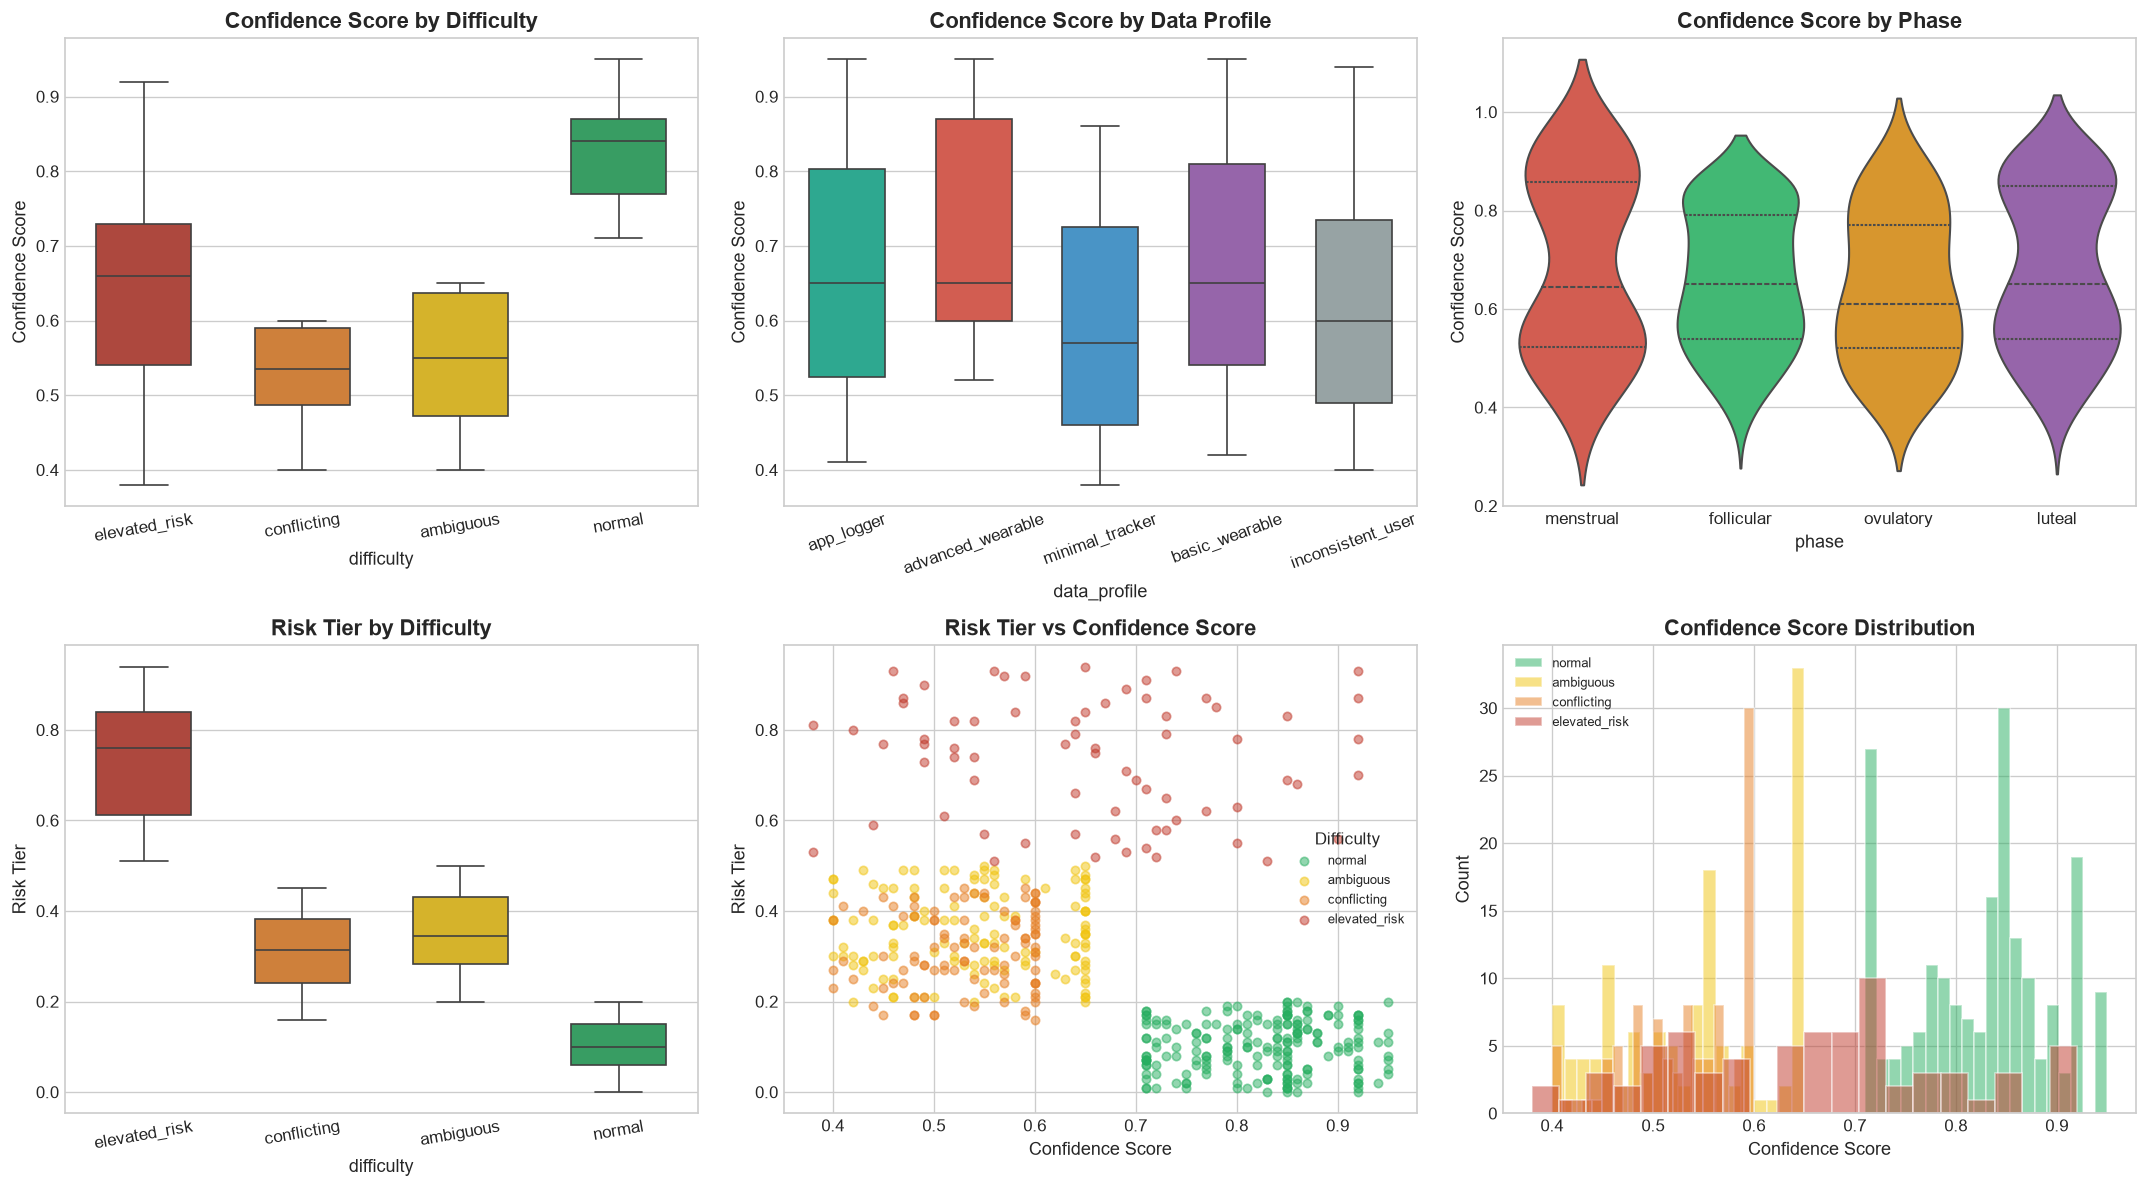


Confidence Score Statistics:
               count   mean    std   min    25%    50%    75%   max
difficulty                                                         
ambiguous      130.0  0.543  0.081  0.40  0.472  0.550  0.638  0.65
conflicting    100.0  0.532  0.059  0.40  0.488  0.535  0.590  0.60
elevated_risk   70.0  0.654  0.139  0.38  0.540  0.660  0.730  0.92
normal         200.0  0.825  0.069  0.71  0.770  0.840  0.870  0.95

Risk Tier Statistics:
               count   mean    std   min    25%    50%    75%   max
difficulty                                                         
ambiguous      130.0  0.352  0.089  0.20  0.283  0.345  0.430  0.50
conflicting    100.0  0.313  0.084  0.16  0.240  0.315  0.382  0.45
elevated_risk   70.0  0.734  0.133  0.51  0.612  0.760  0.840  0.94
normal         200.0  0.100  0.056  0.00  0.060  0.100  0.150  0.20


In [8]:
# =============================================================
# CELL 8: Confidence Score and Risk Tier Analysis
# =============================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Confidence by difficulty
sns.boxplot(data=df, x='difficulty', y='confidence_score', ax=axes[0, 0],
            palette=DIFFICULTY_COLORS, width=0.6)
axes[0, 0].set_title('Confidence Score by Difficulty', fontweight='bold')
axes[0, 0].set_ylabel('Confidence Score')
axes[0, 0].tick_params(axis='x', rotation=10)

# Confidence by profile
sns.boxplot(data=df, x='data_profile', y='confidence_score', ax=axes[0, 1],
            palette=PROFILE_COLORS, width=0.6)
axes[0, 1].set_title('Confidence Score by Data Profile', fontweight='bold')
axes[0, 1].set_ylabel('Confidence Score')
axes[0, 1].tick_params(axis='x', rotation=20)

# Confidence by phase
sns.violinplot(data=df, x='phase', y='confidence_score', ax=axes[0, 2],
               order=['menstrual', 'follicular', 'ovulatory', 'luteal'],
               palette=PHASE_COLORS, inner='quartile')
axes[0, 2].set_title('Confidence Score by Phase', fontweight='bold')
axes[0, 2].set_ylabel('Confidence Score')

# Risk tier by difficulty
sns.boxplot(data=df, x='difficulty', y='risk_tier', ax=axes[1, 0],
            palette=DIFFICULTY_COLORS, width=0.6)
axes[1, 0].set_title('Risk Tier by Difficulty', fontweight='bold')
axes[1, 0].set_ylabel('Risk Tier')
axes[1, 0].tick_params(axis='x', rotation=10)

# Risk tier vs confidence (scatter)
for diff in ['normal', 'ambiguous', 'conflicting', 'elevated_risk']:
    subset = df[df['difficulty'] == diff]
    axes[1, 1].scatter(subset['confidence_score'], subset['risk_tier'],
                       color=DIFFICULTY_COLORS[diff], alpha=0.5, s=25, label=diff)
axes[1, 1].set_title('Risk Tier vs Confidence Score', fontweight='bold')
axes[1, 1].set_xlabel('Confidence Score')
axes[1, 1].set_ylabel('Risk Tier')
axes[1, 1].legend(title='Difficulty', fontsize=8)

# Confidence histogram by difficulty
for diff in ['normal', 'ambiguous', 'conflicting', 'elevated_risk']:
    subset = df[df['difficulty'] == diff]['confidence_score']
    axes[1, 2].hist(subset, bins=20, alpha=0.5, label=diff,
                    color=DIFFICULTY_COLORS[diff], edgecolor='white')
axes[1, 2].set_title('Confidence Score Distribution', fontweight='bold')
axes[1, 2].set_xlabel('Confidence Score')
axes[1, 2].set_ylabel('Count')
axes[1, 2].legend(fontsize=8)

plt.tight_layout()
plt.savefig('viz_06_confidence_risk.png', bbox_inches='tight')
plt.show()

print("\nConfidence Score Statistics:")
print(df.groupby('difficulty')['confidence_score'].describe().round(3))
print("\nRisk Tier Statistics:")
print(df.groupby('difficulty')['risk_tier'].describe().round(3))

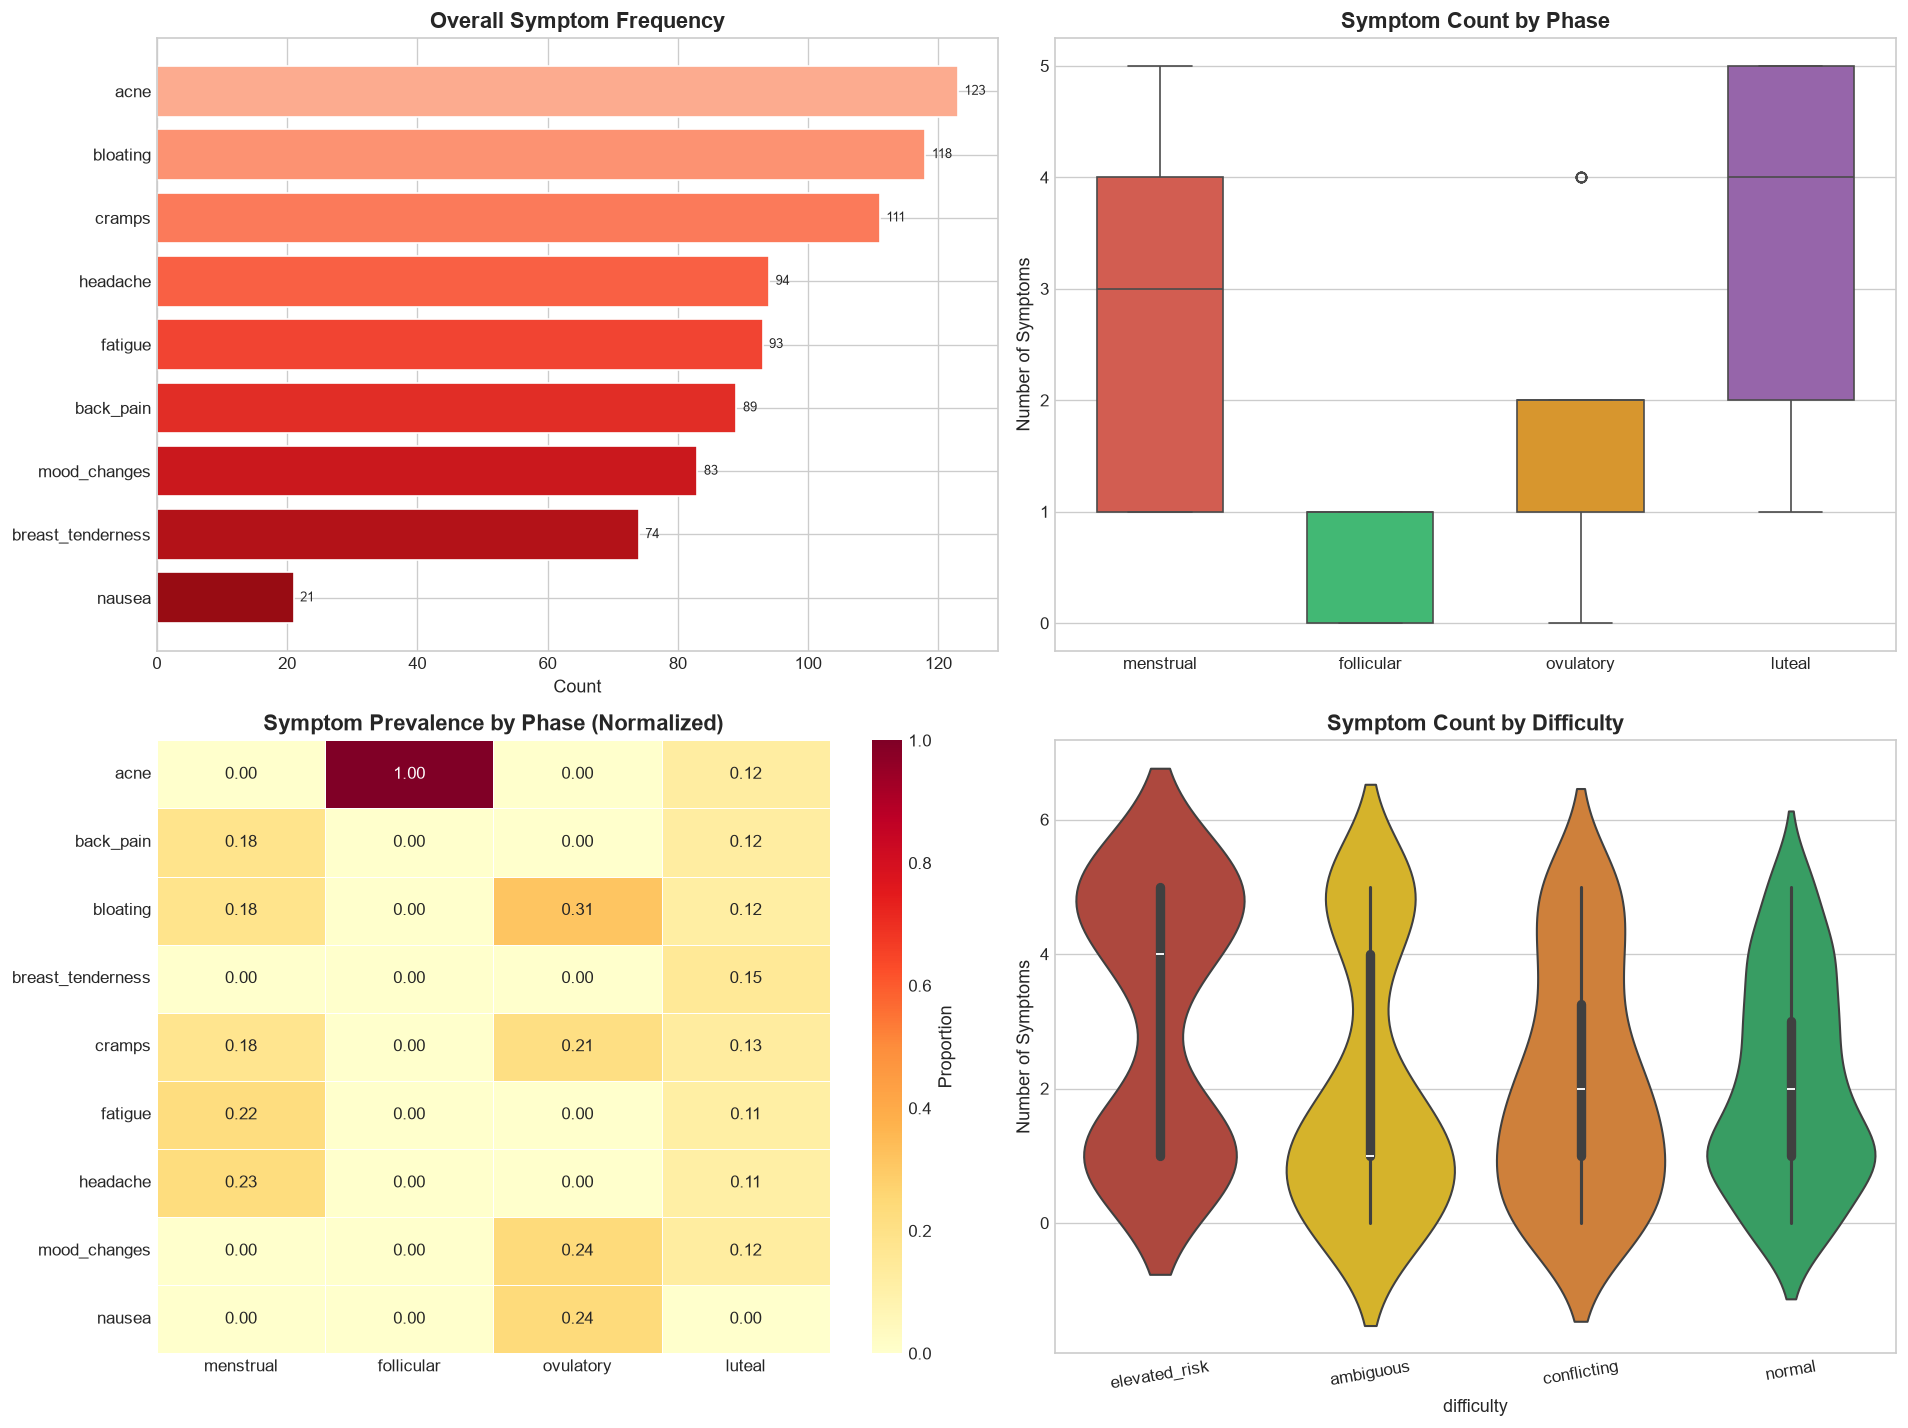


Samples with symptom data: 371
Total symptom occurrences: 806

Mean symptom count by phase:
            mean   std  max
phase                      
follicular  0.55  0.50    1
luteal      3.47  1.55    5
menstrual   2.76  1.37    5
ovulatory   1.56  1.21    4


In [9]:
# =============================================================
# CELL 9: Symptom Analysis
# =============================================================

# Extract symptoms
df_symptoms = df[df['symptoms'].notna()].copy()
df_symptoms['symptom_count'] = df_symptoms['symptoms'].apply(
    lambda x: len([s for s in x if s != 'none']) if isinstance(x, list) else 0
)

# Flatten all symptoms
all_symptom_list = []
for _, row in df_symptoms.iterrows():
    if isinstance(row['symptoms'], list):
        for s in row['symptoms']:
            if s != 'none':
                all_symptom_list.append({'symptom': s, 'phase': row['phase'],
                                         'difficulty': row['difficulty']})

df_flat_symptoms = pd.DataFrame(all_symptom_list)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Overall symptom frequency
symptom_counts = df_flat_symptoms['symptom'].value_counts()
colors_bar = plt.cm.Reds(np.linspace(0.3, 0.9, len(symptom_counts)))
axes[0, 0].barh(symptom_counts.index[::-1], symptom_counts.values[::-1],
                color=colors_bar[::-1], edgecolor='white')
axes[0, 0].set_title('Overall Symptom Frequency', fontweight='bold')
axes[0, 0].set_xlabel('Count')
for i, (idx, val) in enumerate(zip(symptom_counts.index[::-1], symptom_counts.values[::-1])):
    axes[0, 0].text(val + 1, i, str(val), va='center', fontsize=8)

# Symptom count by phase
sns.boxplot(data=df_symptoms, x='phase', y='symptom_count', ax=axes[0, 1],
            order=['menstrual', 'follicular', 'ovulatory', 'luteal'],
            palette=PHASE_COLORS, width=0.6)
axes[0, 1].set_title('Symptom Count by Phase', fontweight='bold')
axes[0, 1].set_ylabel('Number of Symptoms')
axes[0, 1].set_xlabel('')

# Symptom prevalence heatmap by phase
symptom_phase = pd.crosstab(df_flat_symptoms['symptom'], df_flat_symptoms['phase'],
                            normalize='columns')
symptom_phase = symptom_phase[['menstrual', 'follicular', 'ovulatory', 'luteal']]
sns.heatmap(symptom_phase, annot=True, fmt='.2f', cmap='YlOrRd',
            ax=axes[1, 0], linewidths=0.5, cbar_kws={'label': 'Proportion'})
axes[1, 0].set_title('Symptom Prevalence by Phase (Normalized)', fontweight='bold')
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('')

# Symptom count by difficulty
sns.violinplot(data=df_symptoms, x='difficulty', y='symptom_count',
               ax=axes[1, 1], palette=DIFFICULTY_COLORS, inner='box')
axes[1, 1].set_title('Symptom Count by Difficulty', fontweight='bold')
axes[1, 1].set_ylabel('Number of Symptoms')
axes[1, 1].tick_params(axis='x', rotation=10)

plt.tight_layout()
plt.savefig('viz_07_symptoms_analysis.png', bbox_inches='tight')
plt.show()

print(f"\nSamples with symptom data: {len(df_symptoms)}")
print(f"Total symptom occurrences: {len(df_flat_symptoms)}")
print(f"\nMean symptom count by phase:")
print(df_symptoms.groupby('phase')['symptom_count'].agg(['mean', 'std', 'max']).round(2))

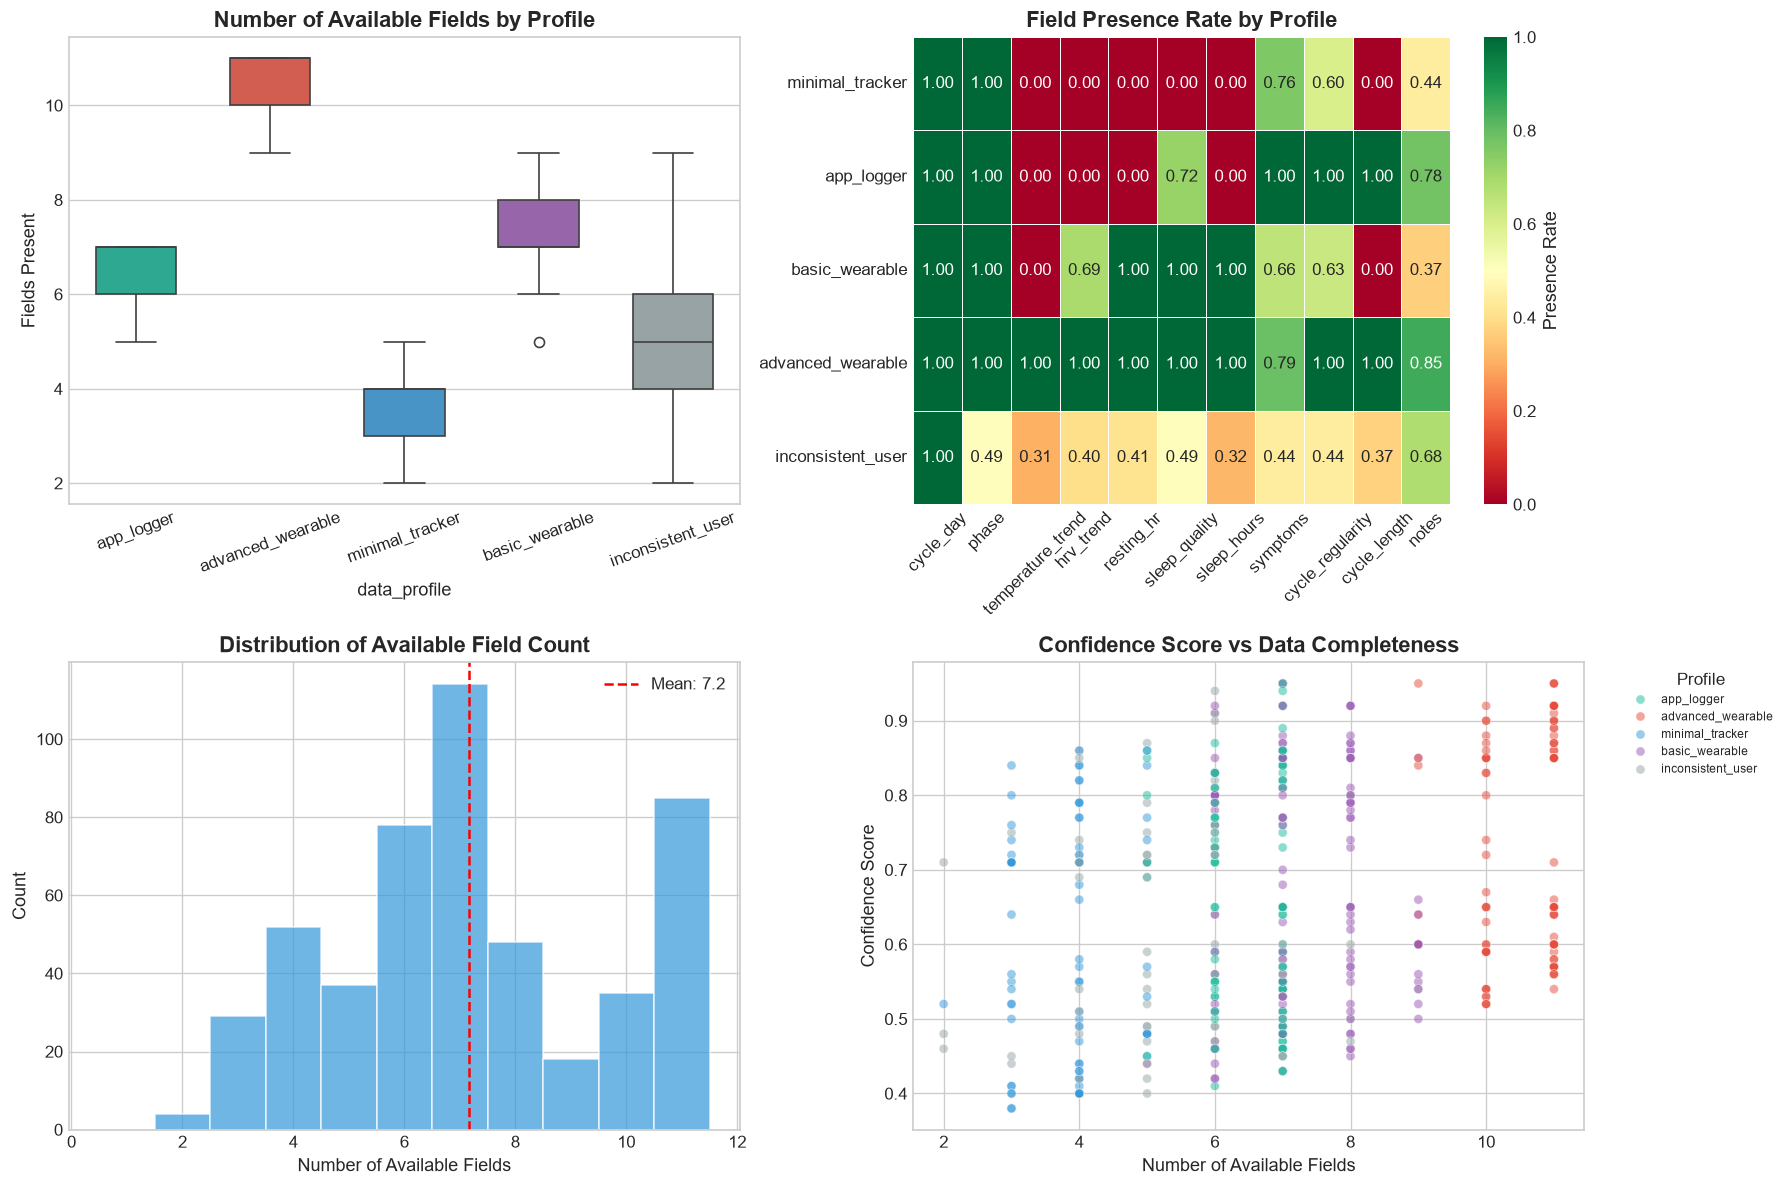


Mean available fields by profile:
                    mean   std  min  max
data_profile                            
advanced_wearable  10.64  0.56    9   11
app_logger          6.50  0.61    5    7
basic_wearable      7.34  0.91    5    9
inconsistent_user   5.36  1.52    2    9
minimal_tracker     3.80  0.72    2    5


In [11]:
# =============================================================
# CELL 10: Data Completeness Analysis
# =============================================================

# Calculate fields per sample
df['n_available'] = df['available_fields'].apply(len)
df['n_missing'] = df['missing_fields'].apply(len)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Available fields by profile
sns.boxplot(data=df, x='data_profile', y='n_available', ax=axes[0, 0],
            palette=PROFILE_COLORS, width=0.6)
axes[0, 0].set_title('Number of Available Fields by Profile', fontweight='bold')
axes[0, 0].set_ylabel('Fields Present')
axes[0, 0].tick_params(axis='x', rotation=20)

# Heatmap: field presence by profile
field_list = ['cycle_day', 'phase', 'temperature_trend', 'hrv_trend',
              'resting_hr', 'sleep_quality', 'sleep_hours', 'symptoms',
              'cycle_regularity', 'cycle_length', 'notes']

presence_matrix = pd.DataFrame(index=PROFILE_COLORS.keys(), columns=field_list, dtype=float)
for profile in PROFILE_COLORS.keys():
    profile_df = df[df['data_profile'] == profile]
    for field in field_list:
        presence_rate = profile_df['available_fields'].apply(lambda x: field in x).mean()
        presence_matrix.loc[profile, field] = presence_rate

presence_matrix = presence_matrix.astype(float)
sns.heatmap(presence_matrix, annot=True, fmt='.2f', cmap='RdYlGn',
            ax=axes[0, 1], linewidths=0.5, vmin=0, vmax=1,
            cbar_kws={'label': 'Presence Rate'})
axes[0, 1].set_title('Field Presence Rate by Profile', fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].tick_params(axis='x', rotation=45)

# Distribution of available field counts
axes[1, 0].hist(df['n_available'], bins=range(1, 13), edgecolor='white',
                color='#3498db', alpha=0.7, align='left')
axes[1, 0].set_title('Distribution of Available Field Count', fontweight='bold')
axes[1, 0].set_xlabel('Number of Available Fields')
axes[1, 0].set_ylabel('Count')
axes[1, 0].axvline(df['n_available'].mean(), color='red', linestyle='--',
                   label=f"Mean: {df['n_available'].mean():.1f}")
axes[1, 0].legend()

# Confidence vs data completeness
sns.scatterplot(data=df, x='n_available', y='confidence_score', hue='data_profile',
                ax=axes[1, 1], palette=PROFILE_COLORS, alpha=0.5, s=30)
axes[1, 1].set_title('Confidence Score vs Data Completeness', fontweight='bold')
axes[1, 1].set_xlabel('Number of Available Fields')
axes[1, 1].set_ylabel('Confidence Score')
axes[1, 1].legend(title='Profile', fontsize=7, bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.savefig('viz_08_data_completeness.png', bbox_inches='tight')
plt.show()

print("\nMean available fields by profile:")
print(df.groupby('data_profile')['n_available'].agg(['mean', 'std', 'min', 'max']).round(2))

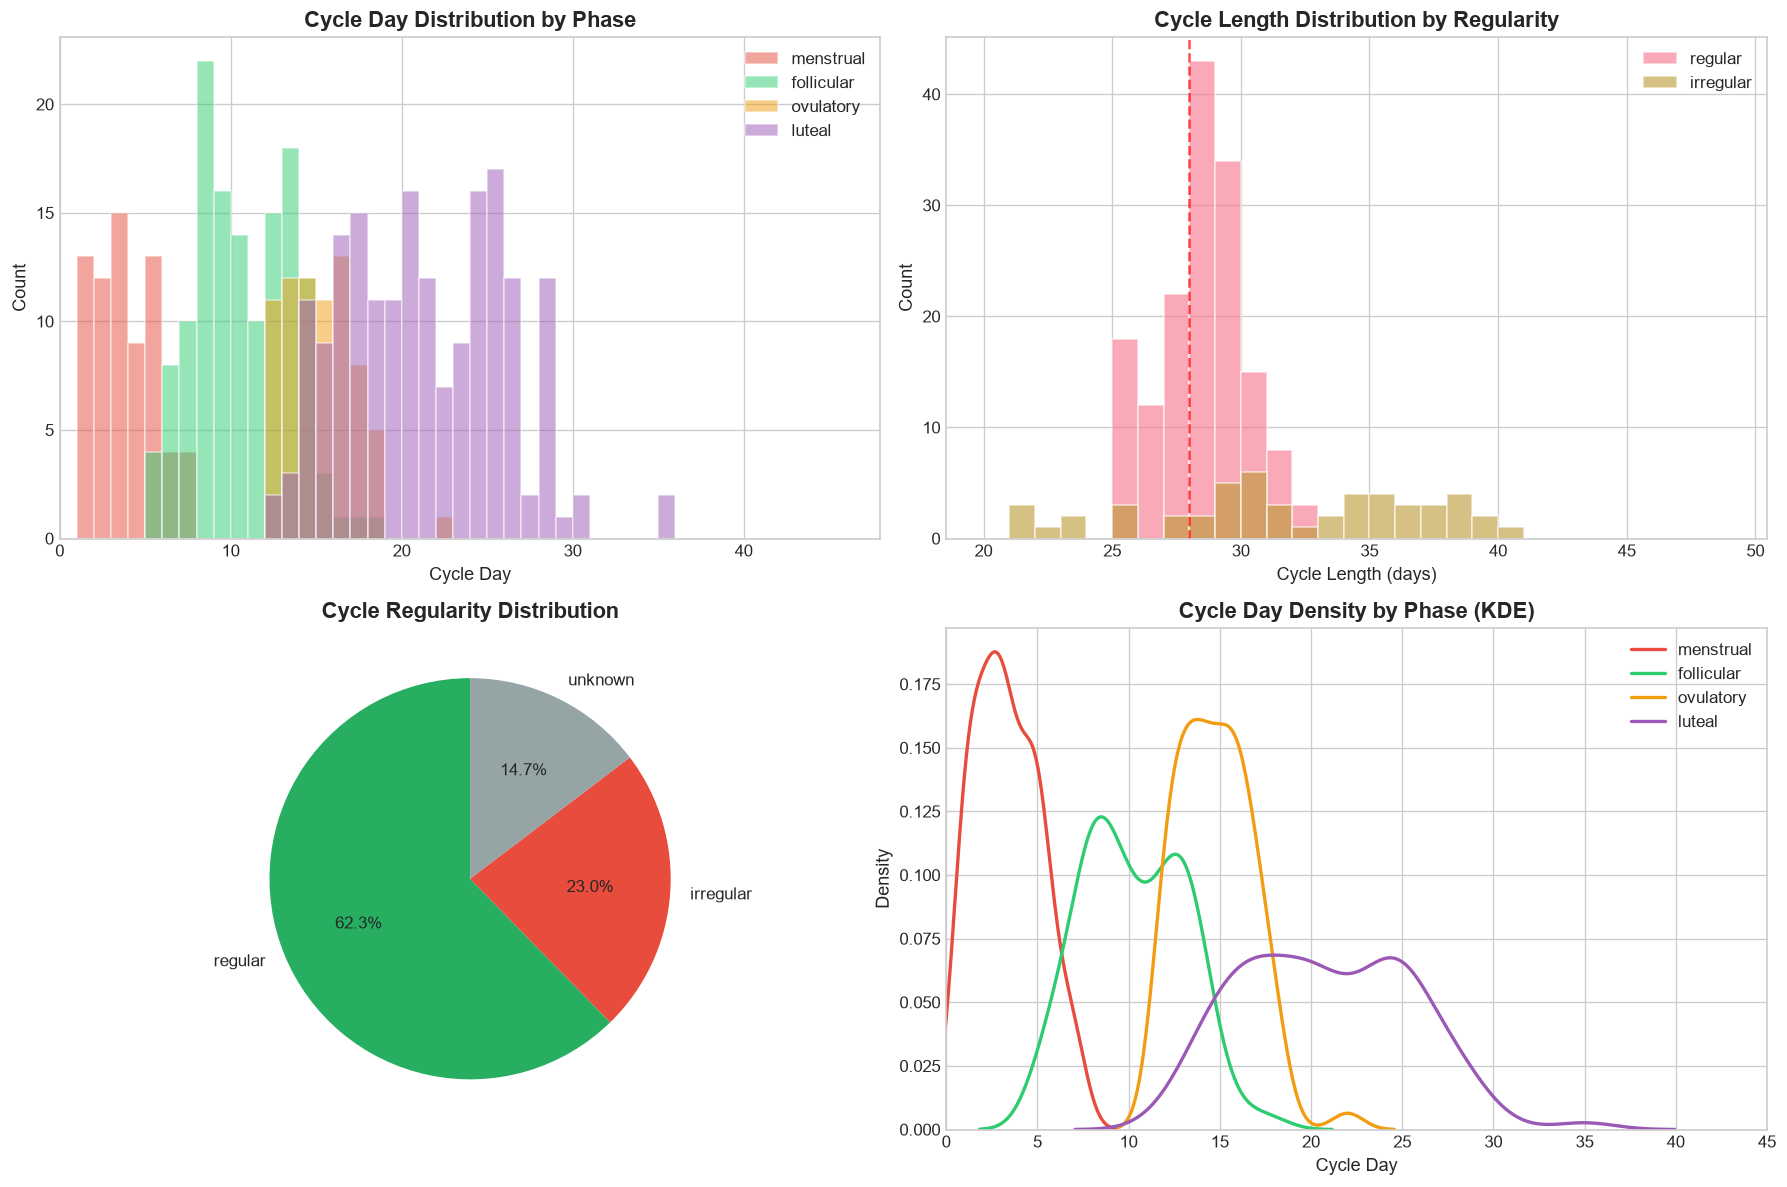


Samples with cycle_length: 217

Cycle length stats:
                  count  mean  std   min   25%   50%   75%   max
cycle_regularity                                                
irregular          51.0  31.3  5.3  21.0  28.5  31.0  35.5  40.0
regular           155.0  28.0  1.7  25.0  27.0  28.0  29.0  32.0


In [12]:
# =============================================================
# CELL 11: Cycle Day and Cycle Length Analysis
# =============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Cycle day distribution by phase
for phase in ['menstrual', 'follicular', 'ovulatory', 'luteal']:
    subset = df[df['phase'] == phase]['cycle_day']
    axes[0, 0].hist(subset, bins=range(1, 50), alpha=0.5, label=phase,
                    color=PHASE_COLORS[phase], edgecolor='white')
axes[0, 0].set_title('Cycle Day Distribution by Phase', fontweight='bold')
axes[0, 0].set_xlabel('Cycle Day')
axes[0, 0].set_ylabel('Count')
axes[0, 0].legend()
axes[0, 0].set_xlim(0, 48)

# Cycle length distribution
df_cl = df[df['cycle_length'].notna()].copy()
df_cl['cycle_length'] = df_cl['cycle_length'].astype(float)

if len(df_cl) > 0:
    for reg in ['regular', 'irregular']:
        subset = df_cl[df_cl['cycle_regularity'] == reg]['cycle_length']
        if len(subset) > 0:
            axes[0, 1].hist(subset, bins=range(20, 50), alpha=0.6, label=reg,
                            edgecolor='white')
    axes[0, 1].set_title('Cycle Length Distribution by Regularity', fontweight='bold')
    axes[0, 1].set_xlabel('Cycle Length (days)')
    axes[0, 1].set_ylabel('Count')
    axes[0, 1].legend()
    axes[0, 1].axvline(28, color='red', linestyle='--', alpha=0.7, label='28-day ref')

# Cycle regularity pie
df_reg = df[df['cycle_regularity'].notna()]
reg_counts = df_reg['cycle_regularity'].value_counts()
reg_colors = ['#27ae60', '#e74c3c', '#95a5a6']
axes[1, 0].pie(reg_counts.values, labels=reg_counts.index, colors=reg_colors,
               autopct='%1.1f%%', startangle=90, textprops={'fontsize': 10})
axes[1, 0].set_title('Cycle Regularity Distribution', fontweight='bold')

# Cycle day KDE by phase
for phase in ['menstrual', 'follicular', 'ovulatory', 'luteal']:
    subset = df[df['phase'] == phase]['cycle_day']
    if len(subset) > 5:
        sns.kdeplot(subset, ax=axes[1, 1], label=phase,
                    color=PHASE_COLORS[phase], linewidth=2)
axes[1, 1].set_title('Cycle Day Density by Phase (KDE)', fontweight='bold')
axes[1, 1].set_xlabel('Cycle Day')
axes[1, 1].set_ylabel('Density')
axes[1, 1].legend()
axes[1, 1].set_xlim(0, 45)

plt.tight_layout()
plt.savefig('viz_09_cycle_analysis.png', bbox_inches='tight')
plt.show()

print(f"\nSamples with cycle_length: {len(df_cl)}")
if len(df_cl) > 0:
    print(f"\nCycle length stats:")
    print(df_cl.groupby('cycle_regularity')['cycle_length'].describe().round(1))

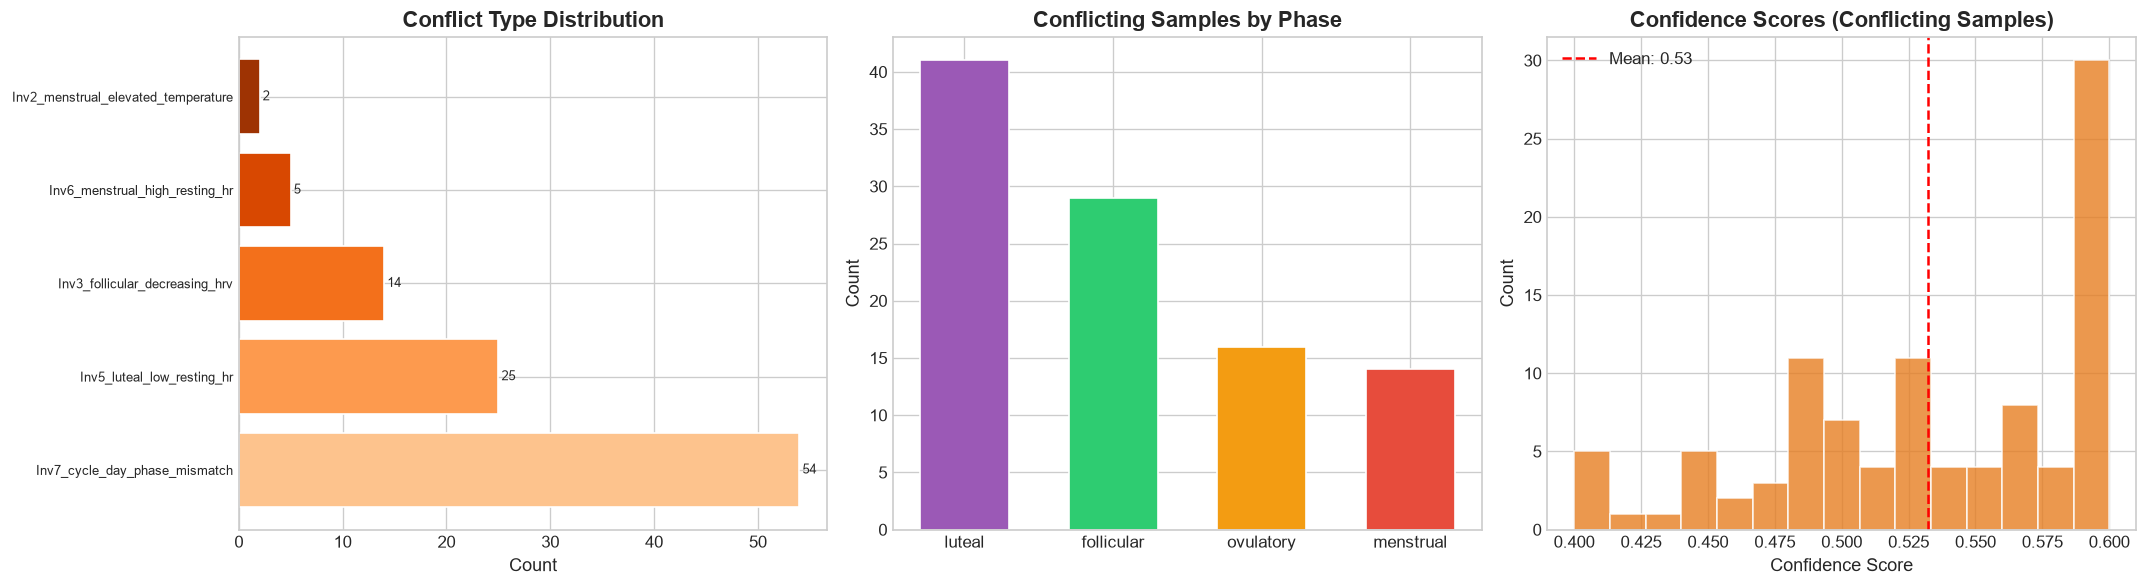


Total conflicting samples: 100

Conflict type breakdown:
conflict_type
invariant_7_cycle_day_phase_mismatch          54
invariant_5_luteal_low_resting_hr             25
invariant_3_follicular_decreasing_hrv         14
invariant_6_menstrual_high_resting_hr          5
invariant_2_menstrual_elevated_temperature     2


In [13]:
# =============================================================
# CELL 12: Conflict Analysis (for "conflicting" difficulty)
# =============================================================

df_conflict = df[df['difficulty'] == 'conflicting'].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Conflict types
if 'conflict_type' in df_conflict.columns:
    conflict_types = df_conflict['conflict_type'].value_counts()

    # Shorten labels for readability
    short_labels = [ct.replace('invariant_', 'Inv').replace('_in_', '\nin ')[:40]
                    for ct in conflict_types.index]

    colors_ct = plt.cm.Oranges(np.linspace(0.3, 0.9, len(conflict_types)))
    axes[0].barh(range(len(conflict_types)), conflict_types.values,
                 color=colors_ct, edgecolor='white')
    axes[0].set_yticks(range(len(conflict_types)))
    axes[0].set_yticklabels(short_labels, fontsize=8)
    axes[0].set_title('Conflict Type Distribution', fontweight='bold')
    axes[0].set_xlabel('Count')
    for i, val in enumerate(conflict_types.values):
        axes[0].text(val + 0.3, i, str(val), va='center', fontsize=8)
else:
    axes[0].text(0.5, 0.5, 'No conflict_type field found',
                 transform=axes[0].transAxes, ha='center')

# Conflicting samples by phase
phase_conflict = df_conflict['phase'].value_counts()
axes[1].bar(phase_conflict.index, phase_conflict.values,
            color=[PHASE_COLORS.get(p, '#999') for p in phase_conflict.index],
            edgecolor='white', width=0.6)
axes[1].set_title('Conflicting Samples by Phase', fontweight='bold')
axes[1].set_ylabel('Count')

# Confidence score distribution for conflicting
axes[2].hist(df_conflict['confidence_score'], bins=15, color='#e67e22',
             edgecolor='white', alpha=0.8)
axes[2].axvline(df_conflict['confidence_score'].mean(), color='red',
                linestyle='--', label=f"Mean: {df_conflict['confidence_score'].mean():.2f}")
axes[2].set_title('Confidence Scores (Conflicting Samples)', fontweight='bold')
axes[2].set_xlabel('Confidence Score')
axes[2].set_ylabel('Count')
axes[2].legend()

plt.tight_layout()
plt.savefig('viz_10_conflict_analysis.png', bbox_inches='tight')
plt.show()

print(f"\nTotal conflicting samples: {len(df_conflict)}")
if 'conflict_type' in df_conflict.columns:
    print(f"\nConflict type breakdown:")
    print(df_conflict['conflict_type'].value_counts().to_string())

ValueError: The palette dictionary is missing keys: {'False', 'True'}

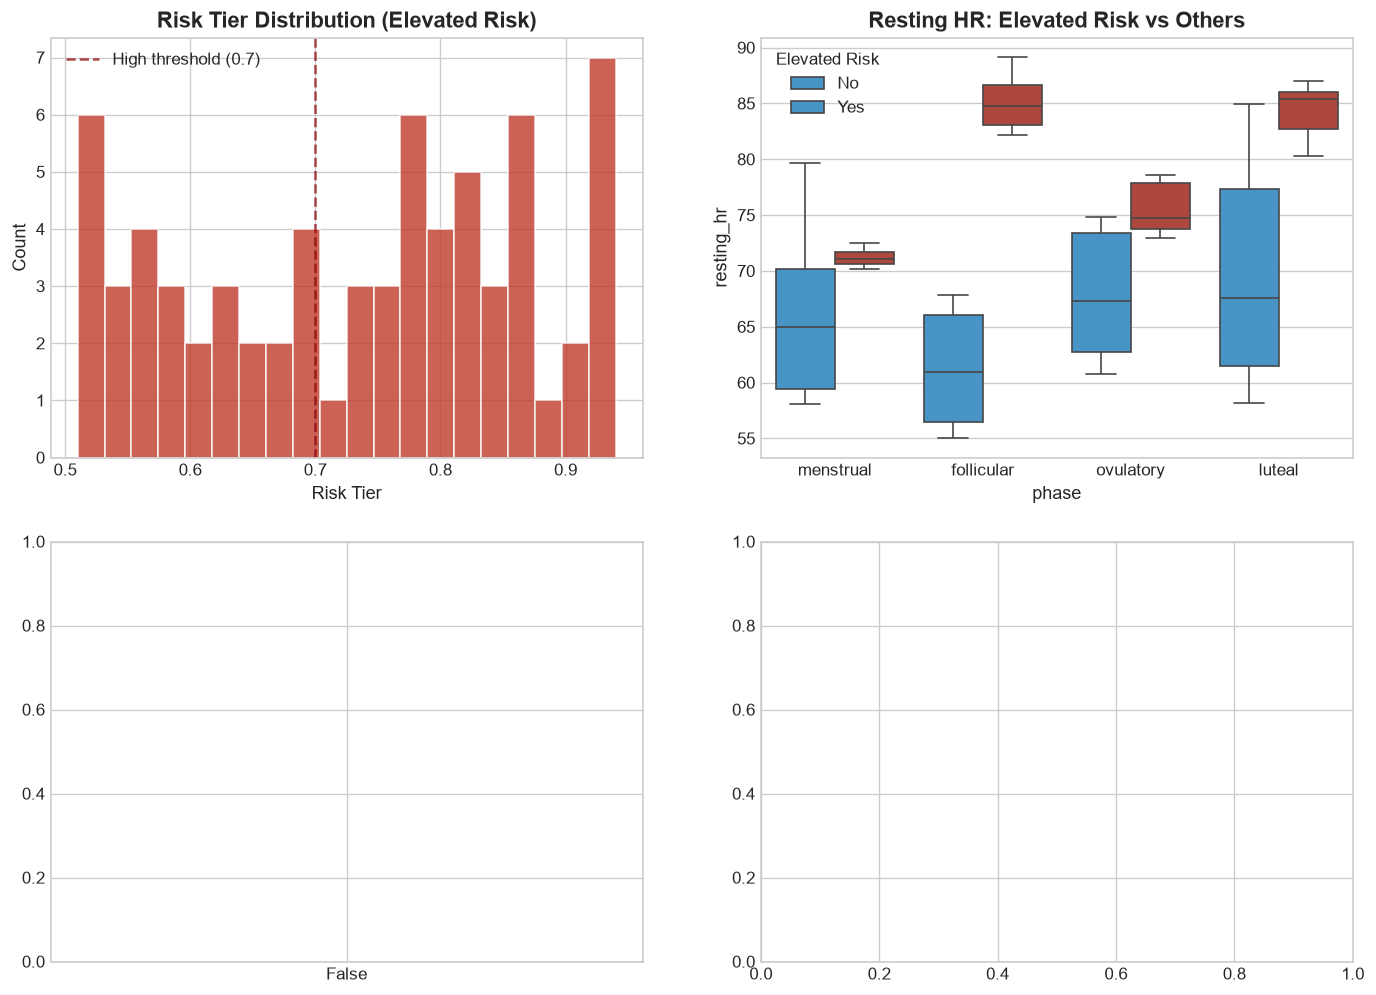

In [14]:
# =============================================================
# CELL 13: Elevated Risk Analysis
# =============================================================

df_risk = df[df['difficulty'] == 'elevated_risk'].copy()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Risk tier distribution
axes[0, 0].hist(df_risk['risk_tier'], bins=20, color='#c0392b',
                edgecolor='white', alpha=0.8)
axes[0, 0].set_title('Risk Tier Distribution (Elevated Risk)', fontweight='bold')
axes[0, 0].set_xlabel('Risk Tier')
axes[0, 0].set_ylabel('Count')
axes[0, 0].axvline(0.7, color='darkred', linestyle='--', alpha=0.7,
                   label='High threshold (0.7)')
axes[0, 0].legend()

# Resting HR for elevated risk vs others
df_hr_risk = df[df['resting_hr'].notna()].copy()
df_hr_risk['is_elevated'] = df_hr_risk['difficulty'] == 'elevated_risk'
sns.boxplot(data=df_hr_risk, x='phase', y='resting_hr', hue='is_elevated',
            ax=axes[0, 1], palette={True: '#c0392b', False: '#3498db'},
            order=['menstrual', 'follicular', 'ovulatory', 'luteal'])
axes[0, 1].set_title('Resting HR: Elevated Risk vs Others', fontweight='bold')
axes[0, 1].legend(title='Elevated Risk', labels=['No', 'Yes'])

# Sleep hours for elevated risk
df_sh_risk = df[df['sleep_hours'].notna()].copy()
df_sh_risk['is_elevated'] = df_sh_risk['difficulty'] == 'elevated_risk'
sns.violinplot(data=df_sh_risk, x='is_elevated', y='sleep_hours',
               ax=axes[1, 0], palette={True: '#c0392b', False: '#3498db'},
               inner='quartile')
axes[1, 0].set_title('Sleep Hours: Elevated Risk vs Others', fontweight='bold')
axes[1, 0].set_xticklabels(['Normal/Ambiguous/Conflict', 'Elevated Risk'])
axes[1, 0].set_ylabel('Sleep Hours')

# Symptom count for elevated risk
df_sym = df[df['symptoms'].notna()].copy()
df_sym['symptom_count'] = df_sym['symptoms'].apply(
    lambda x: len([s for s in x if s != 'none']) if isinstance(x, list) else 0
)
df_sym['is_elevated'] = df_sym['difficulty'] == 'elevated_risk'
sns.boxplot(data=df_sym, x='phase', y='symptom_count', hue='is_elevated',
            ax=axes[1, 1], palette={True: '#c0392b', False: '#3498db'},
            order=['menstrual', 'follicular', 'ovulatory', 'luteal'])
axes[1, 1].set_title('Symptom Count: Elevated Risk vs Others', fontweight='bold')
axes[1, 1].set_ylabel('Symptom Count')
axes[1, 1].legend(title='Elevated Risk', labels=['No', 'Yes'])

plt.tight_layout()
plt.savefig('viz_11_elevated_risk.png', bbox_inches='tight')
plt.show()

print(f"\nElevated risk samples: {len(df_risk)}")
print(f"Mean risk tier: {df_risk['risk_tier'].mean():.3f}")
print(f"Samples with HR > 80 (elevated_risk): "
      f"{len(df_risk[df_risk['resting_hr'].notna() & (df_risk['resting_hr'] > 80)])}")

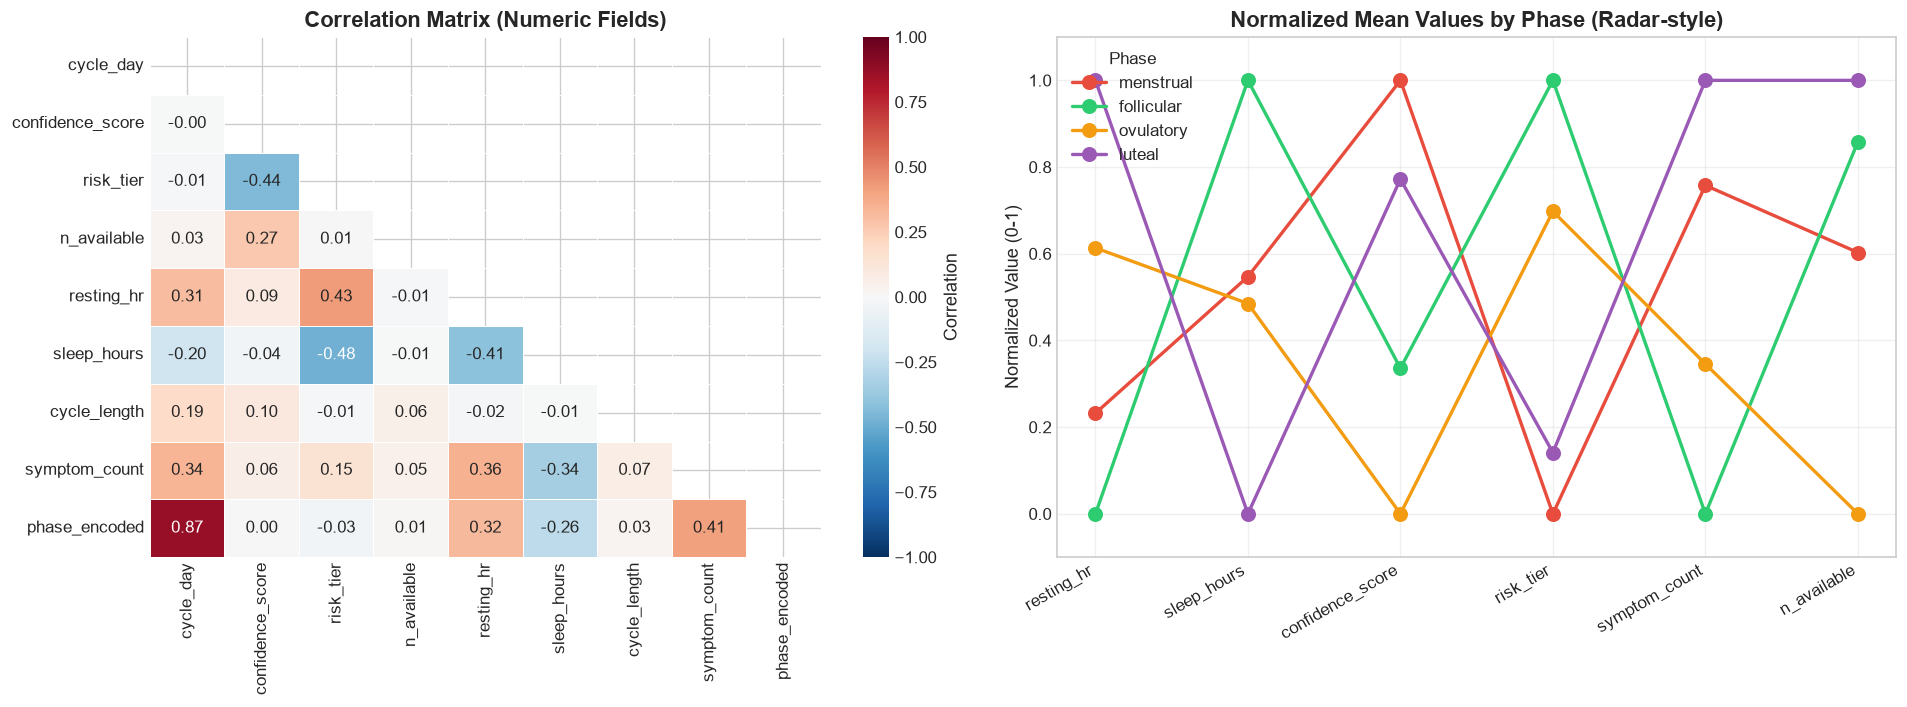


Correlation highlights:
  Confidence ↔ Data Completeness: 0.271
  Risk Tier ↔ Confidence: -0.442
  Resting HR ↔ Sleep Hours: -0.407


In [15]:
# =============================================================
# CELL 14: Correlation and Multi-Dimensional Analysis
# =============================================================

# Prepare numeric DataFrame for correlation
df_numeric = df[['cycle_day', 'confidence_score', 'risk_tier', 'n_available']].copy()
df_numeric['resting_hr'] = df['resting_hr']
df_numeric['sleep_hours'] = df['sleep_hours']
df_numeric['cycle_length'] = pd.to_numeric(df['cycle_length'], errors='coerce')
df_numeric['symptom_count'] = df['symptoms'].apply(
    lambda x: len([s for s in x if s != 'none']) if isinstance(x, list) else np.nan
)

# Encode categoricals for correlation
phase_map = {'menstrual': 0, 'follicular': 1, 'ovulatory': 2, 'luteal': 3}
df_numeric['phase_encoded'] = df['phase'].map(phase_map)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Correlation heatmap
corr = df_numeric.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            ax=axes[0], linewidths=0.5, center=0, vmin=-1, vmax=1,
            cbar_kws={'label': 'Correlation'})
axes[0].set_title('Correlation Matrix (Numeric Fields)', fontweight='bold')

# Parallel coordinates-like: mean values per phase (normalized)
means_by_phase = df_numeric.groupby(df['phase']).mean()
# Normalize to 0-1 range for comparison
means_norm = (means_by_phase - means_by_phase.min()) / (means_by_phase.max() - means_by_phase.min() + 1e-8)

fields_to_plot = ['resting_hr', 'sleep_hours', 'confidence_score',
                  'risk_tier', 'symptom_count', 'n_available']
means_norm_sub = means_norm[fields_to_plot].T

x = range(len(fields_to_plot))
for phase in ['menstrual', 'follicular', 'ovulatory', 'luteal']:
    if phase in means_norm_sub.columns:
        axes[1].plot(x, means_norm_sub[phase], 'o-', label=phase,
                     color=PHASE_COLORS[phase], linewidth=2, markersize=8)

axes[1].set_xticks(x)
axes[1].set_xticklabels(fields_to_plot, rotation=30, ha='right')
axes[1].set_ylabel('Normalized Value (0-1)')
axes[1].set_title('Normalized Mean Values by Phase (Radar-style)', fontweight='bold')
axes[1].legend(title='Phase')
axes[1].set_ylim(-0.1, 1.1)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('viz_12_correlation_multivariate.png', bbox_inches='tight')
plt.show()

print("\nCorrelation highlights:")
print(f"  Confidence ↔ Data Completeness: {corr.loc['confidence_score', 'n_available']:.3f}")
print(f"  Risk Tier ↔ Confidence: {corr.loc['risk_tier', 'confidence_score']:.3f}")
if 'resting_hr' in corr.columns and 'sleep_hours' in corr.columns:
    val = corr.loc['resting_hr', 'sleep_hours']
    if not np.isnan(val):
        print(f"  Resting HR ↔ Sleep Hours: {val:.3f}")

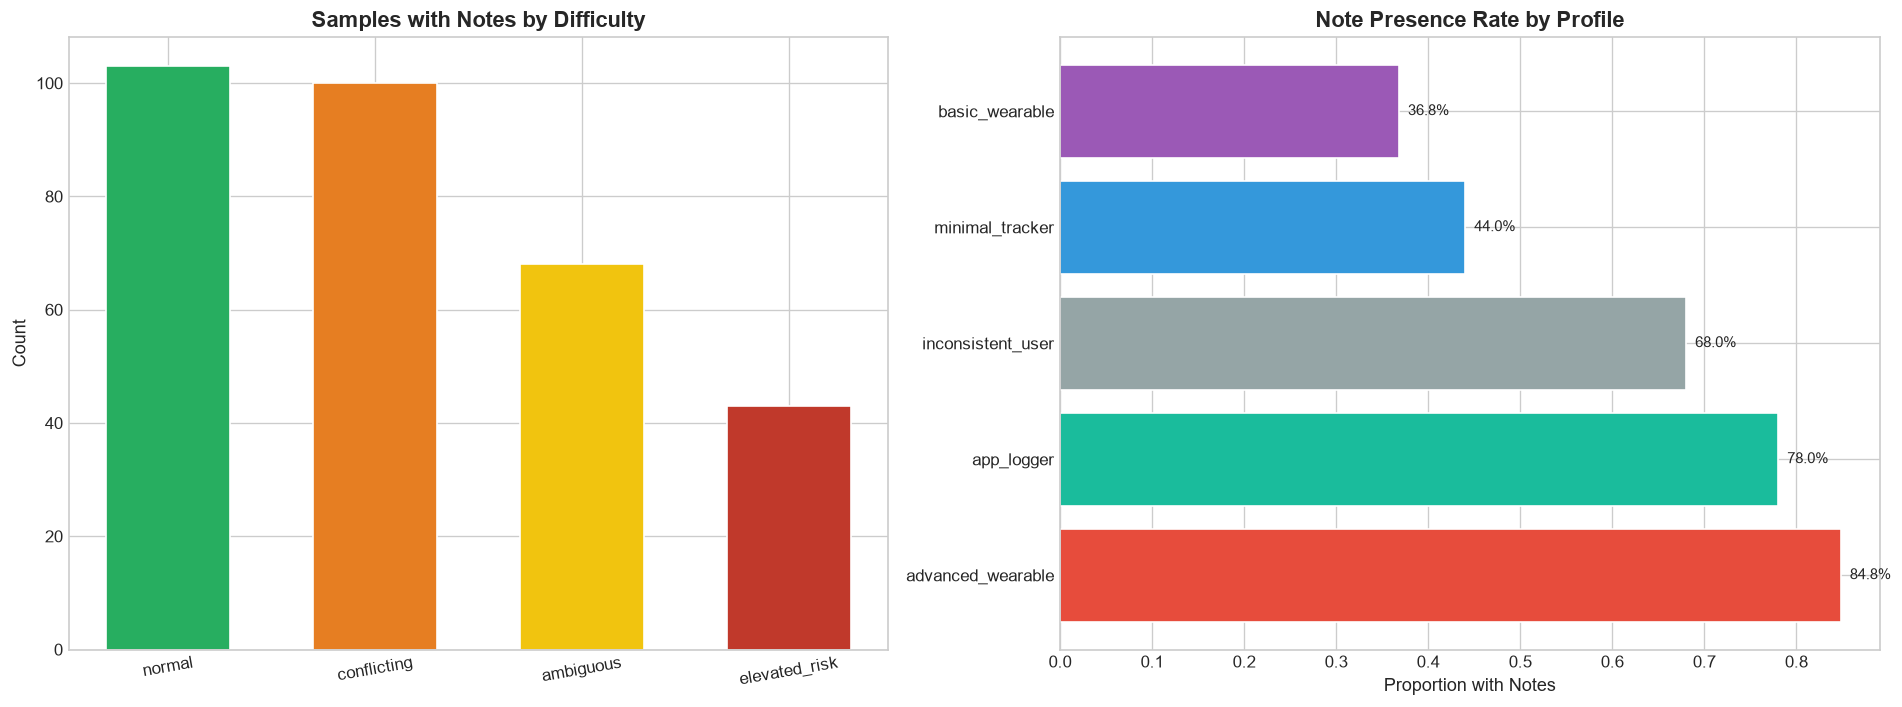


Total samples with notes: 314 (62.8%)

Most common notes:
  [ 13] reduced alcohol intake
  [ 13] high training load
  [ 11] limited screen time before bed
  [ 11] increased caffeine intake
  [ 11] late bedtime past 3 nights
  [  9] new skincare routine
  [  9] night shift this week
  [  9] reduced caffeine intake
  [  8] attended social event late
  [  8] slept in a new environment
  [  8] took ibuprofen for cramps
  [  8] took antihistamine
  [  8] recovering from cold
  [  7] missed morning workout
  [  7] mild seasonal allergies


In [16]:
# =============================================================
# CELL 15: Notes / Free-Text Analysis
# =============================================================

df_notes = df[df['notes'].notna()].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Note frequency by difficulty
notes_by_diff = df_notes['difficulty'].value_counts()
axes[0].bar(notes_by_diff.index, notes_by_diff.values,
            color=[DIFFICULTY_COLORS[d] for d in notes_by_diff.index],
            edgecolor='white', width=0.6)
axes[0].set_title('Samples with Notes by Difficulty', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=10)

# Calculate note presence rate per profile
note_rate = df.groupby('data_profile').apply(
    lambda x: x['notes'].notna().mean()
).sort_values(ascending=False)

axes[1].barh(note_rate.index, note_rate.values,
             color=[PROFILE_COLORS[p] for p in note_rate.index],
             edgecolor='white')
axes[1].set_title('Note Presence Rate by Profile', fontweight='bold')
axes[1].set_xlabel('Proportion with Notes')
for i, (idx, val) in enumerate(note_rate.items()):
    axes[1].text(val + 0.01, i, f'{val:.1%}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('viz_13_notes_analysis.png', bbox_inches='tight')
plt.show()

# Word/phrase frequency in notes
print(f"\nTotal samples with notes: {len(df_notes)} ({len(df_notes)/500*100:.1f}%)")
print(f"\nMost common notes:")
note_counts = df_notes['notes'].value_counts().head(15)
for note, count in note_counts.items():
    print(f"  [{count:3d}] {note}")

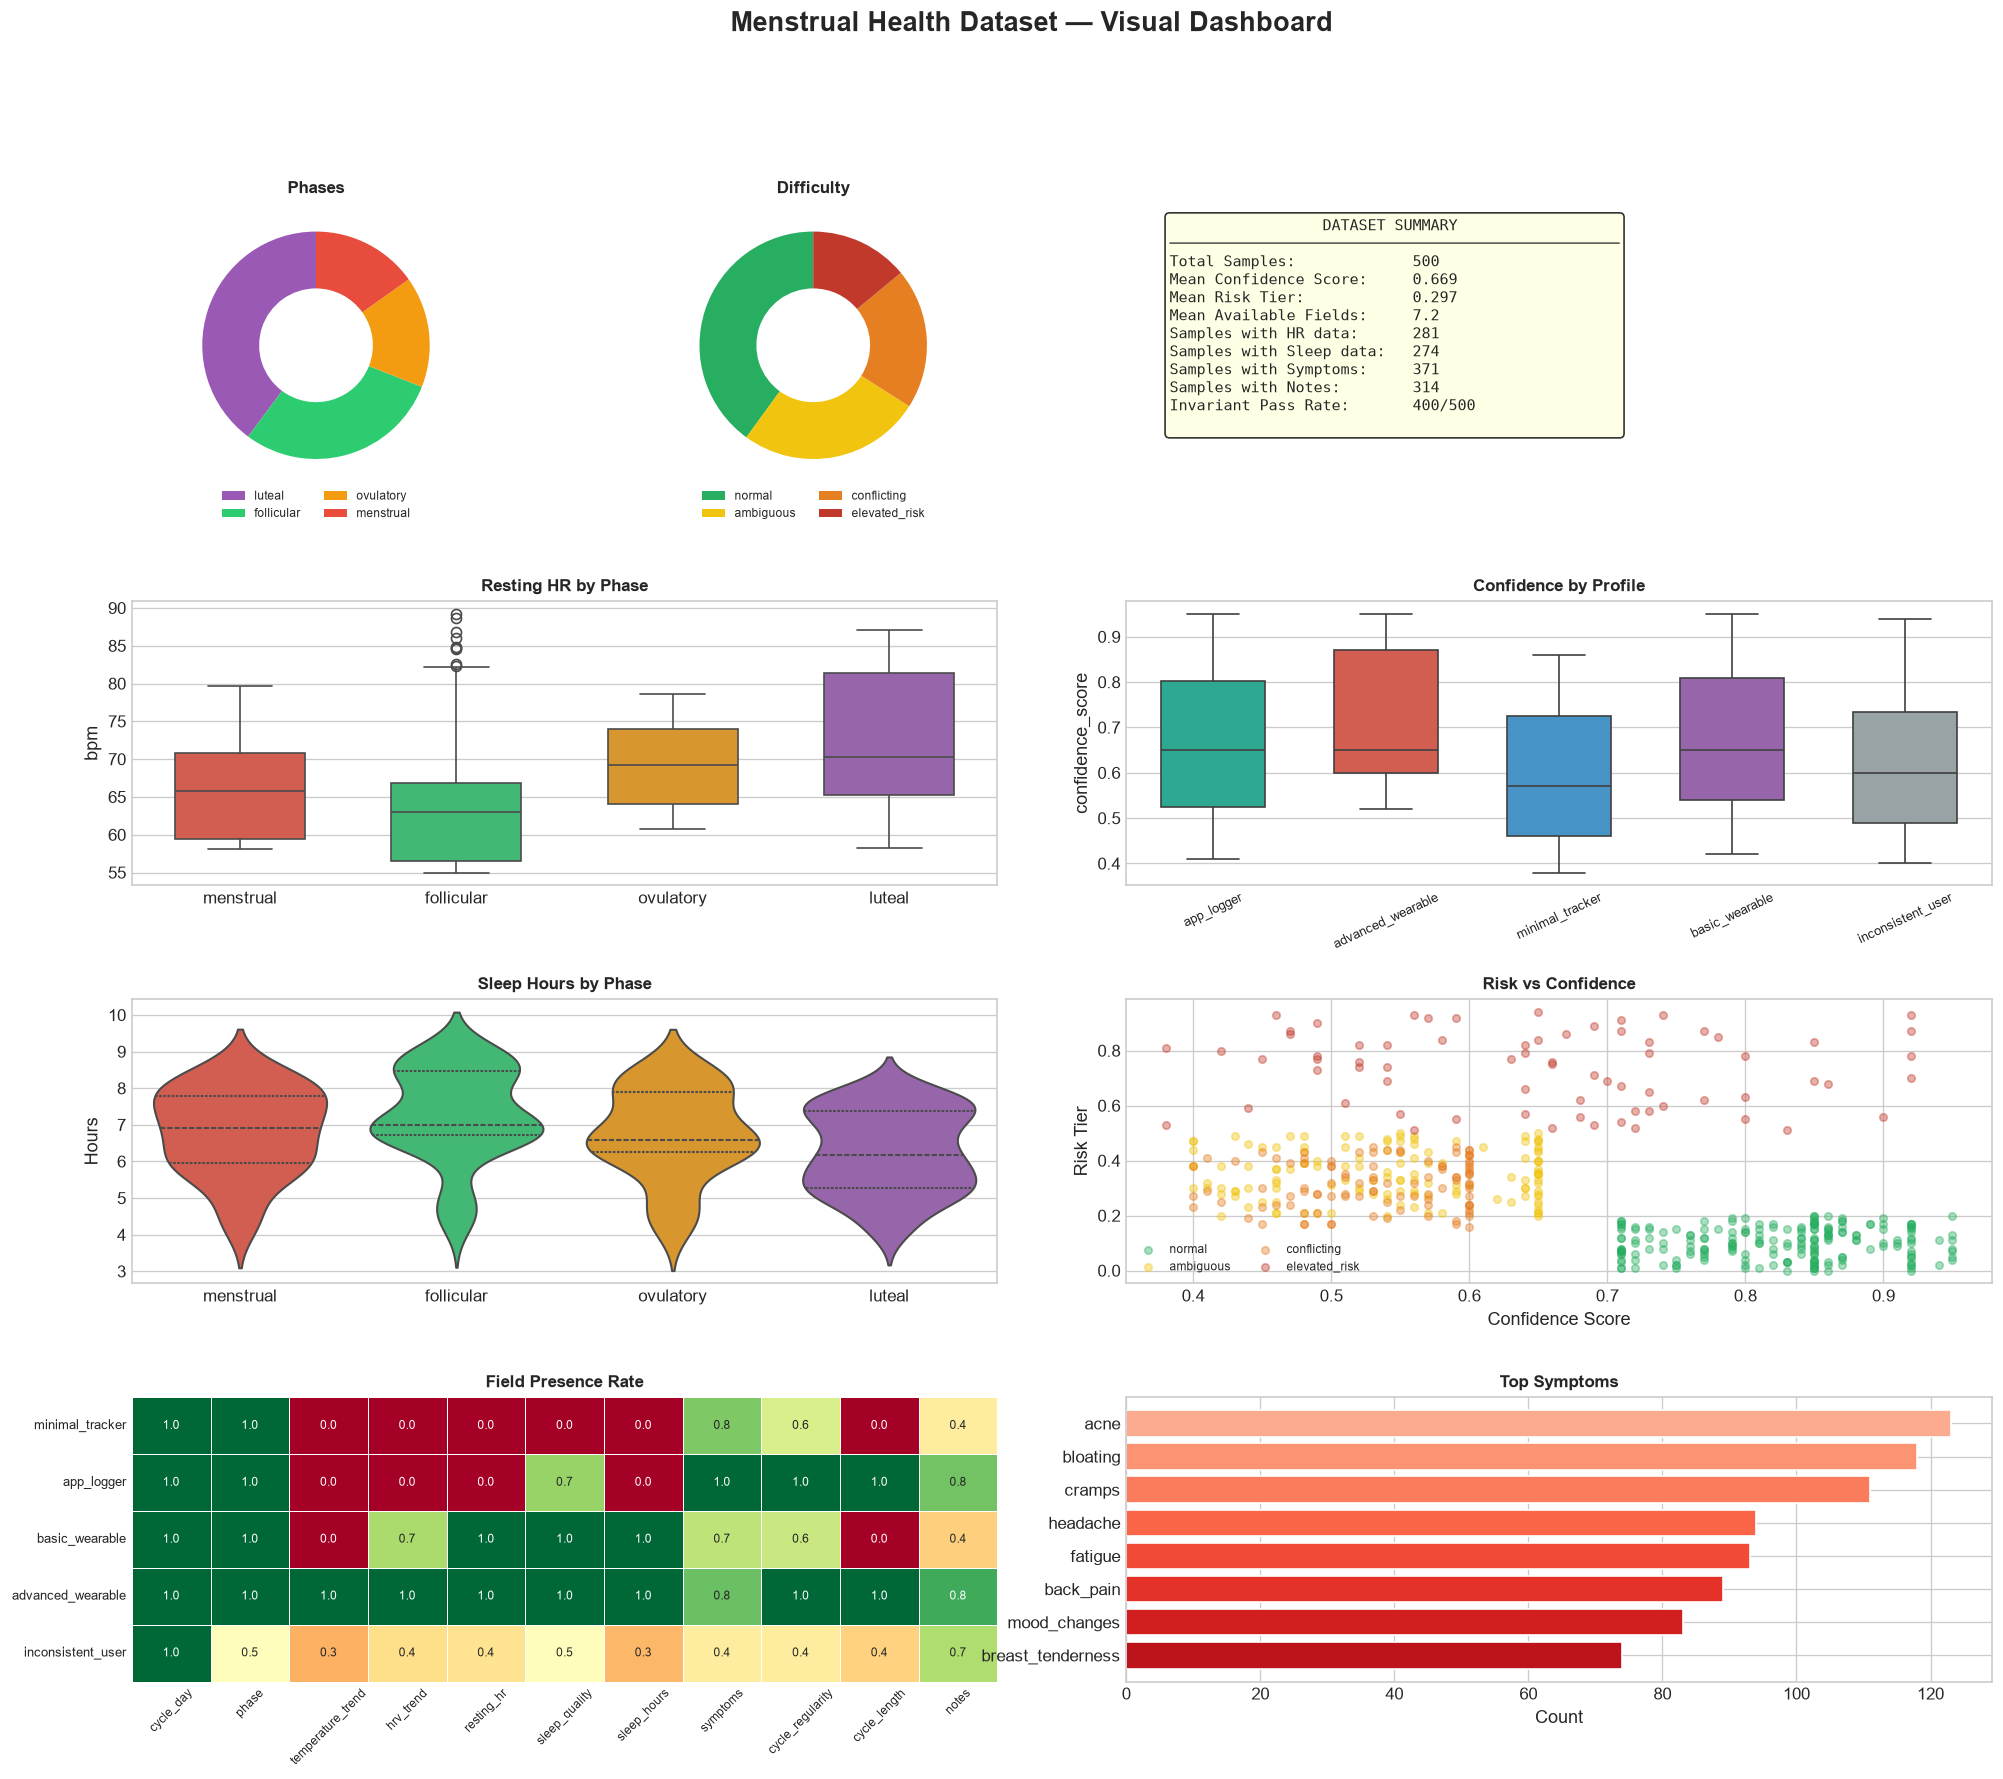

In [17]:
# =============================================================
# CELL 16: Comprehensive Dashboard Summary
# =============================================================

fig = plt.figure(figsize=(20, 16))
gs = fig.add_gridspec(4, 4, hspace=0.4, wspace=0.35)

# ---- Row 1 ----
# Phase donut
ax1 = fig.add_subplot(gs[0, 0])
phase_counts = df['phase'].value_counts()
wedges, texts = ax1.pie(phase_counts.values,
                        colors=[PHASE_COLORS[p] for p in phase_counts.index],
                        startangle=90, wedgeprops=dict(width=0.5))
ax1.set_title('Phases', fontweight='bold', fontsize=10)
ax1.legend(phase_counts.index, loc='lower center', fontsize=7, ncol=2,
           bbox_to_anchor=(0.5, -0.15))

# Difficulty donut
ax2 = fig.add_subplot(gs[0, 1])
diff_counts = df['difficulty'].value_counts()
ax2.pie(diff_counts.values,
        colors=[DIFFICULTY_COLORS[d] for d in diff_counts.index],
        startangle=90, wedgeprops=dict(width=0.5))
ax2.set_title('Difficulty', fontweight='bold', fontsize=10)
ax2.legend(diff_counts.index, loc='lower center', fontsize=7, ncol=2,
           bbox_to_anchor=(0.5, -0.15))

# Key metrics text
ax3 = fig.add_subplot(gs[0, 2:4])
ax3.axis('off')
metrics_text = (
    f"{'DATASET SUMMARY':^50}\n"
    f"{'─' * 50}\n"
    f"Total Samples:             500\n"
    f"Mean Confidence Score:     {df['confidence_score'].mean():.3f}\n"
    f"Mean Risk Tier:            {df['risk_tier'].mean():.3f}\n"
    f"Mean Available Fields:     {df['n_available'].mean():.1f}\n"
    f"Samples with HR data:      {df['resting_hr'].notna().sum()}\n"
    f"Samples with Sleep data:   {df['sleep_hours'].notna().sum()}\n"
    f"Samples with Symptoms:     {df['symptoms'].notna().sum()}\n"
    f"Samples with Notes:        {df['notes'].notna().sum()}\n"
    f"Invariant Pass Rate:       {metadata['invariant_validation']['passed']}/{metadata['invariant_validation']['total_checked']}\n"
)
ax3.text(0.05, 0.95, metrics_text, transform=ax3.transAxes,
         fontsize=9, verticalalignment='top', fontfamily='monospace',
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

# ---- Row 2 ----
# HR by phase
ax4 = fig.add_subplot(gs[1, 0:2])
df_hr_valid = df[df['resting_hr'].notna()]
sns.boxplot(data=df_hr_valid, x='phase', y='resting_hr', ax=ax4,
            order=['menstrual', 'follicular', 'ovulatory', 'luteal'],
            palette=PHASE_COLORS, width=0.6)
ax4.set_title('Resting HR by Phase', fontweight='bold', fontsize=10)
ax4.set_ylabel('bpm')
ax4.set_xlabel('')

# Confidence by profile
ax5 = fig.add_subplot(gs[1, 2:4])
sns.boxplot(data=df, x='data_profile', y='confidence_score', ax=ax5,
            palette=PROFILE_COLORS, width=0.6)
ax5.set_title('Confidence by Profile', fontweight='bold', fontsize=10)
ax5.tick_params(axis='x', rotation=25, labelsize=8)
ax5.set_xlabel('')

# ---- Row 3 ----
# Sleep hours by phase
ax6 = fig.add_subplot(gs[2, 0:2])
df_sl_valid = df[df['sleep_hours'].notna()]
sns.violinplot(data=df_sl_valid, x='phase', y='sleep_hours', ax=ax6,
               order=['menstrual', 'follicular', 'ovulatory', 'luteal'],
               palette=PHASE_COLORS, inner='quartile')
ax6.set_title('Sleep Hours by Phase', fontweight='bold', fontsize=10)
ax6.set_ylabel('Hours')
ax6.set_xlabel('')

# Risk vs Confidence scatter
ax7 = fig.add_subplot(gs[2, 2:4])
for diff in ['normal', 'ambiguous', 'conflicting', 'elevated_risk']:
    subset = df[df['difficulty'] == diff]
    ax7.scatter(subset['confidence_score'], subset['risk_tier'],
                color=DIFFICULTY_COLORS[diff], alpha=0.4, s=20, label=diff)
ax7.set_title('Risk vs Confidence', fontweight='bold', fontsize=10)
ax7.set_xlabel('Confidence Score')
ax7.set_ylabel('Risk Tier')
ax7.legend(fontsize=7, ncol=2)

# ---- Row 4 ----
# Data completeness heatmap (mini)
ax8 = fig.add_subplot(gs[3, 0:2])
sns.heatmap(presence_matrix.astype(float), annot=True, fmt='.1f',
            cmap='RdYlGn', ax=ax8, linewidths=0.3, cbar=False,
            annot_kws={'fontsize': 7}, vmin=0, vmax=1)
ax8.set_title('Field Presence Rate', fontweight='bold', fontsize=10)
ax8.tick_params(axis='x', rotation=45, labelsize=7)
ax8.tick_params(axis='y', labelsize=8)

# Symptom top-10 bar
ax9 = fig.add_subplot(gs[3, 2:4])
if len(df_flat_symptoms) > 0:
    top_symptoms = df_flat_symptoms['symptom'].value_counts().head(8)
    bars = ax9.barh(top_symptoms.index[::-1], top_symptoms.values[::-1],
                    color=plt.cm.Reds(np.linspace(0.3, 0.8, 8))[::-1],
                    edgecolor='white')
    ax9.set_title('Top Symptoms', fontweight='bold', fontsize=10)
    ax9.set_xlabel('Count')

plt.suptitle('Menstrual Health Dataset — Visual Dashboard',
             fontsize=16, fontweight='bold', y=0.98)
plt.savefig('viz_14_dashboard_summary.png', bbox_inches='tight')
plt.show()

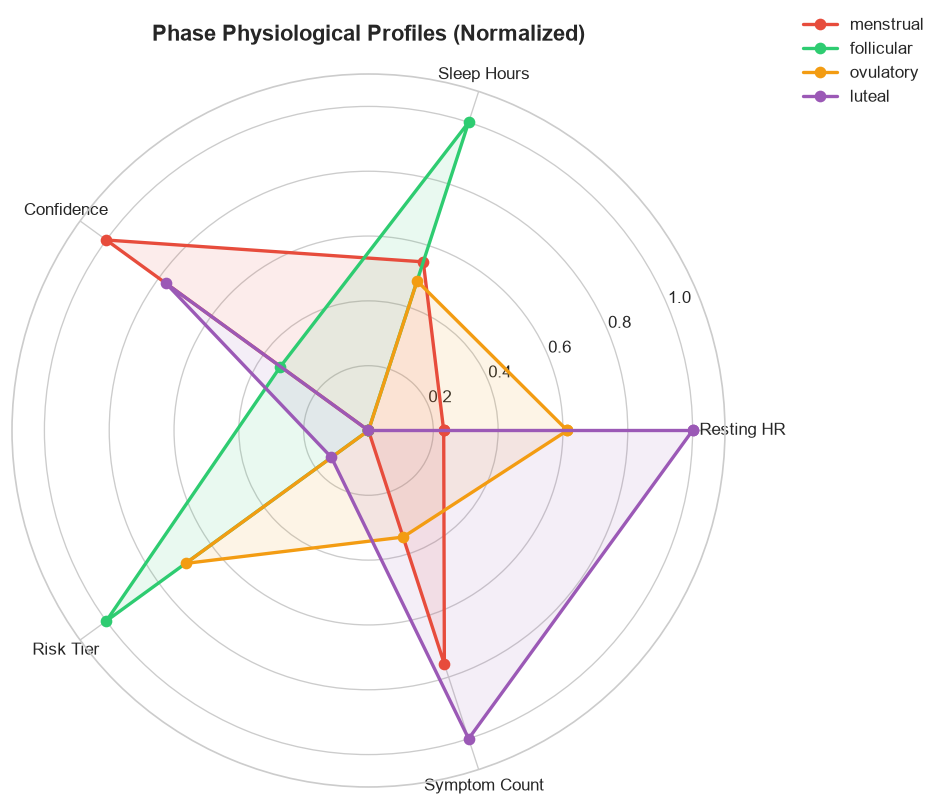


Raw mean values by phase:
            resting_hr  sleep_hours  confidence_score  risk_tier  symptom_count
phase                                                                          
follicular       64.47         7.24              0.66       0.33           0.55
luteal           72.06         6.24              0.68       0.28           3.47
menstrual        66.24         6.79              0.69       0.27           2.76
ovulatory        69.13         6.73              0.64       0.31           1.56


In [18]:
# =============================================================
# CELL 17: Phase-Specific Physiological Profiles (Radar/Spider)
# =============================================================

from matplotlib.patches import FancyBboxPatch
import matplotlib.patches as mpatches

# Compute mean values per phase for radar chart
df_radar = df.copy()
df_radar['symptom_count'] = df_radar['symptoms'].apply(
    lambda x: len([s for s in x if s != 'none']) if isinstance(x, list) else np.nan
)

metrics = ['resting_hr', 'sleep_hours', 'confidence_score', 'risk_tier', 'symptom_count']
phase_means = df_radar.groupby('phase')[metrics].mean()

# Normalize each metric to 0-1
phase_norm = (phase_means - phase_means.min()) / (phase_means.max() - phase_means.min() + 1e-8)

# Radar chart
categories = metrics
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]  # Complete the circle

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for phase in ['menstrual', 'follicular', 'ovulatory', 'luteal']:
    if phase in phase_norm.index:
        values = phase_norm.loc[phase].values.tolist()
        values += values[:1]
        ax.plot(angles, values, 'o-', linewidth=2, label=phase,
                color=PHASE_COLORS[phase])
        ax.fill(angles, values, alpha=0.1, color=PHASE_COLORS[phase])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(['Resting HR', 'Sleep Hours', 'Confidence',
                    'Risk Tier', 'Symptom Count'], fontsize=10)
ax.set_ylim(0, 1.1)
ax.set_title('Phase Physiological Profiles (Normalized)', fontweight='bold',
             fontsize=13, pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)

plt.tight_layout()
plt.savefig('viz_15_radar_profiles.png', bbox_inches='tight')
plt.show()

print("\nRaw mean values by phase:")
print(phase_means.round(2).to_string())

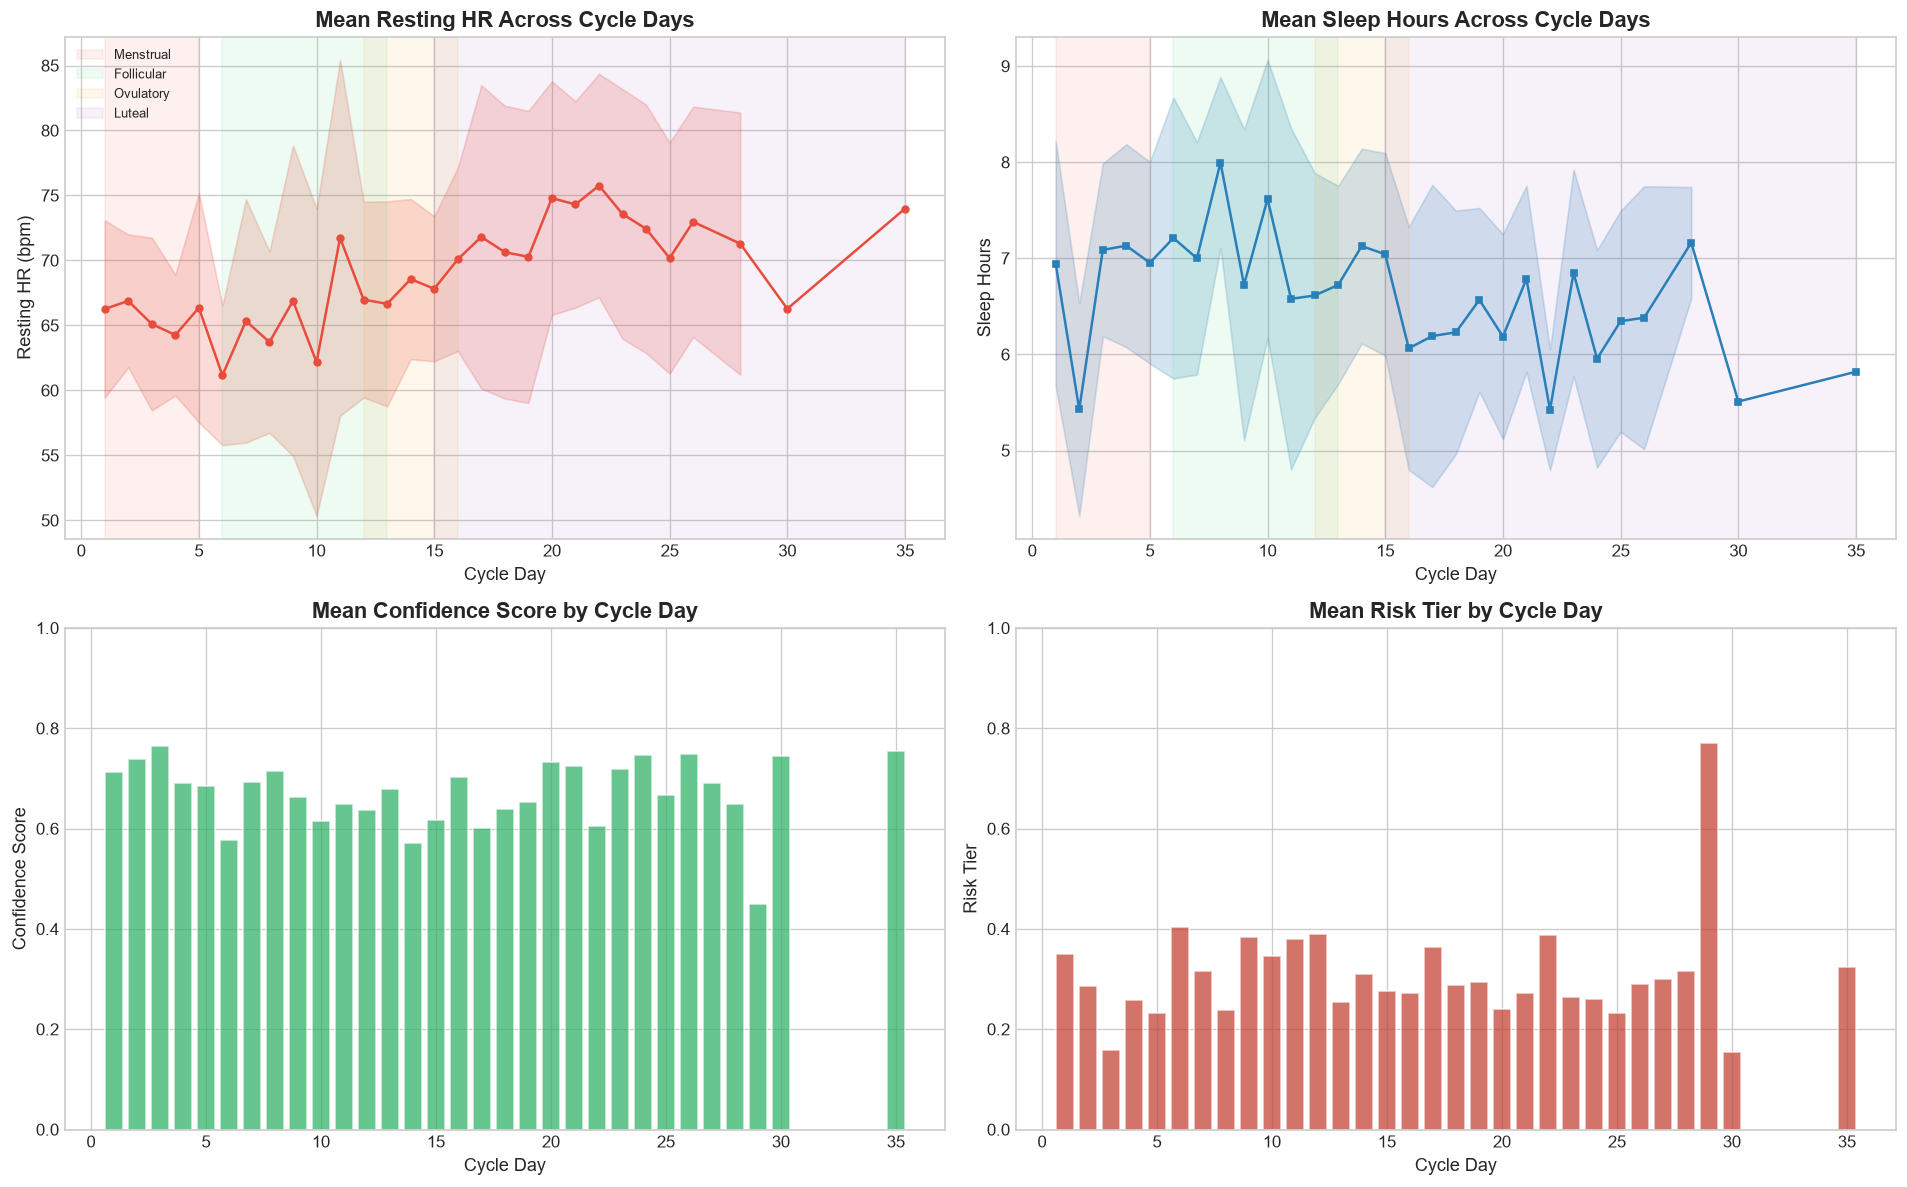

In [19]:
# =============================================================
# CELL 18: Temporal/Cycle Day Progression Visualization
# =============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Group by cycle_day and compute means (only for samples with data)
df_temporal = df.copy()

# HR progression through cycle
df_t_hr = df_temporal[df_temporal['resting_hr'].notna()].copy()
hr_by_day = df_t_hr.groupby('cycle_day')['resting_hr'].agg(['mean', 'std']).reset_index()
hr_by_day = hr_by_day[hr_by_day['cycle_day'] <= 35]

axes[0, 0].plot(hr_by_day['cycle_day'], hr_by_day['mean'], '-o',
                color='#e74c3c', markersize=4, linewidth=1.5)
axes[0, 0].fill_between(hr_by_day['cycle_day'],
                        hr_by_day['mean'] - hr_by_day['std'],
                        hr_by_day['mean'] + hr_by_day['std'],
                        alpha=0.2, color='#e74c3c')
# Phase regions
axes[0, 0].axvspan(1, 5, alpha=0.08, color=PHASE_COLORS['menstrual'], label='Menstrual')
axes[0, 0].axvspan(6, 13, alpha=0.08, color=PHASE_COLORS['follicular'], label='Follicular')
axes[0, 0].axvspan(12, 16, alpha=0.08, color=PHASE_COLORS['ovulatory'], label='Ovulatory')
axes[0, 0].axvspan(15, 35, alpha=0.08, color=PHASE_COLORS['luteal'], label='Luteal')
axes[0, 0].set_title('Mean Resting HR Across Cycle Days', fontweight='bold')
axes[0, 0].set_xlabel('Cycle Day')
axes[0, 0].set_ylabel('Resting HR (bpm)')
axes[0, 0].legend(fontsize=8, loc='upper left')

# Sleep hours progression
df_t_sl = df_temporal[df_temporal['sleep_hours'].notna()].copy()
sl_by_day = df_t_sl.groupby('cycle_day')['sleep_hours'].agg(['mean', 'std']).reset_index()
sl_by_day = sl_by_day[sl_by_day['cycle_day'] <= 35]

axes[0, 1].plot(sl_by_day['cycle_day'], sl_by_day['mean'], '-s',
                color='#2980b9', markersize=4, linewidth=1.5)
axes[0, 1].fill_between(sl_by_day['cycle_day'],
                        sl_by_day['mean'] - sl_by_day['std'],
                        sl_by_day['mean'] + sl_by_day['std'],
                        alpha=0.2, color='#2980b9')
axes[0, 1].axvspan(1, 5, alpha=0.08, color=PHASE_COLORS['menstrual'])
axes[0, 1].axvspan(6, 13, alpha=0.08, color=PHASE_COLORS['follicular'])
axes[0, 1].axvspan(12, 16, alpha=0.08, color=PHASE_COLORS['ovulatory'])
axes[0, 1].axvspan(15, 35, alpha=0.08, color=PHASE_COLORS['luteal'])
axes[0, 1].set_title('Mean Sleep Hours Across Cycle Days', fontweight='bold')
axes[0, 1].set_xlabel('Cycle Day')
axes[0, 1].set_ylabel('Sleep Hours')

# Confidence progression
conf_by_day = df_temporal.groupby('cycle_day')['confidence_score'].mean().reset_index()
conf_by_day = conf_by_day[conf_by_day['cycle_day'] <= 35]
axes[1, 0].bar(conf_by_day['cycle_day'], conf_by_day['confidence_score'],
               color='#27ae60', alpha=0.7, edgecolor='white', width=0.8)
axes[1, 0].set_title('Mean Confidence Score by Cycle Day', fontweight='bold')
axes[1, 0].set_xlabel('Cycle Day')
axes[1, 0].set_ylabel('Confidence Score')
axes[1, 0].set_ylim(0, 1)

# Risk tier progression
risk_by_day = df_temporal.groupby('cycle_day')['risk_tier'].mean().reset_index()
risk_by_day = risk_by_day[risk_by_day['cycle_day'] <= 35]
axes[1, 1].bar(risk_by_day['cycle_day'], risk_by_day['risk_tier'],
               color='#c0392b', alpha=0.7, edgecolor='white', width=0.8)
axes[1, 1].set_title('Mean Risk Tier by Cycle Day', fontweight='bold')
axes[1, 1].set_xlabel('Cycle Day')
axes[1, 1].set_ylabel('Risk Tier')
axes[1, 1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig('viz_16_temporal_progression.png', bbox_inches='tight')
plt.show()

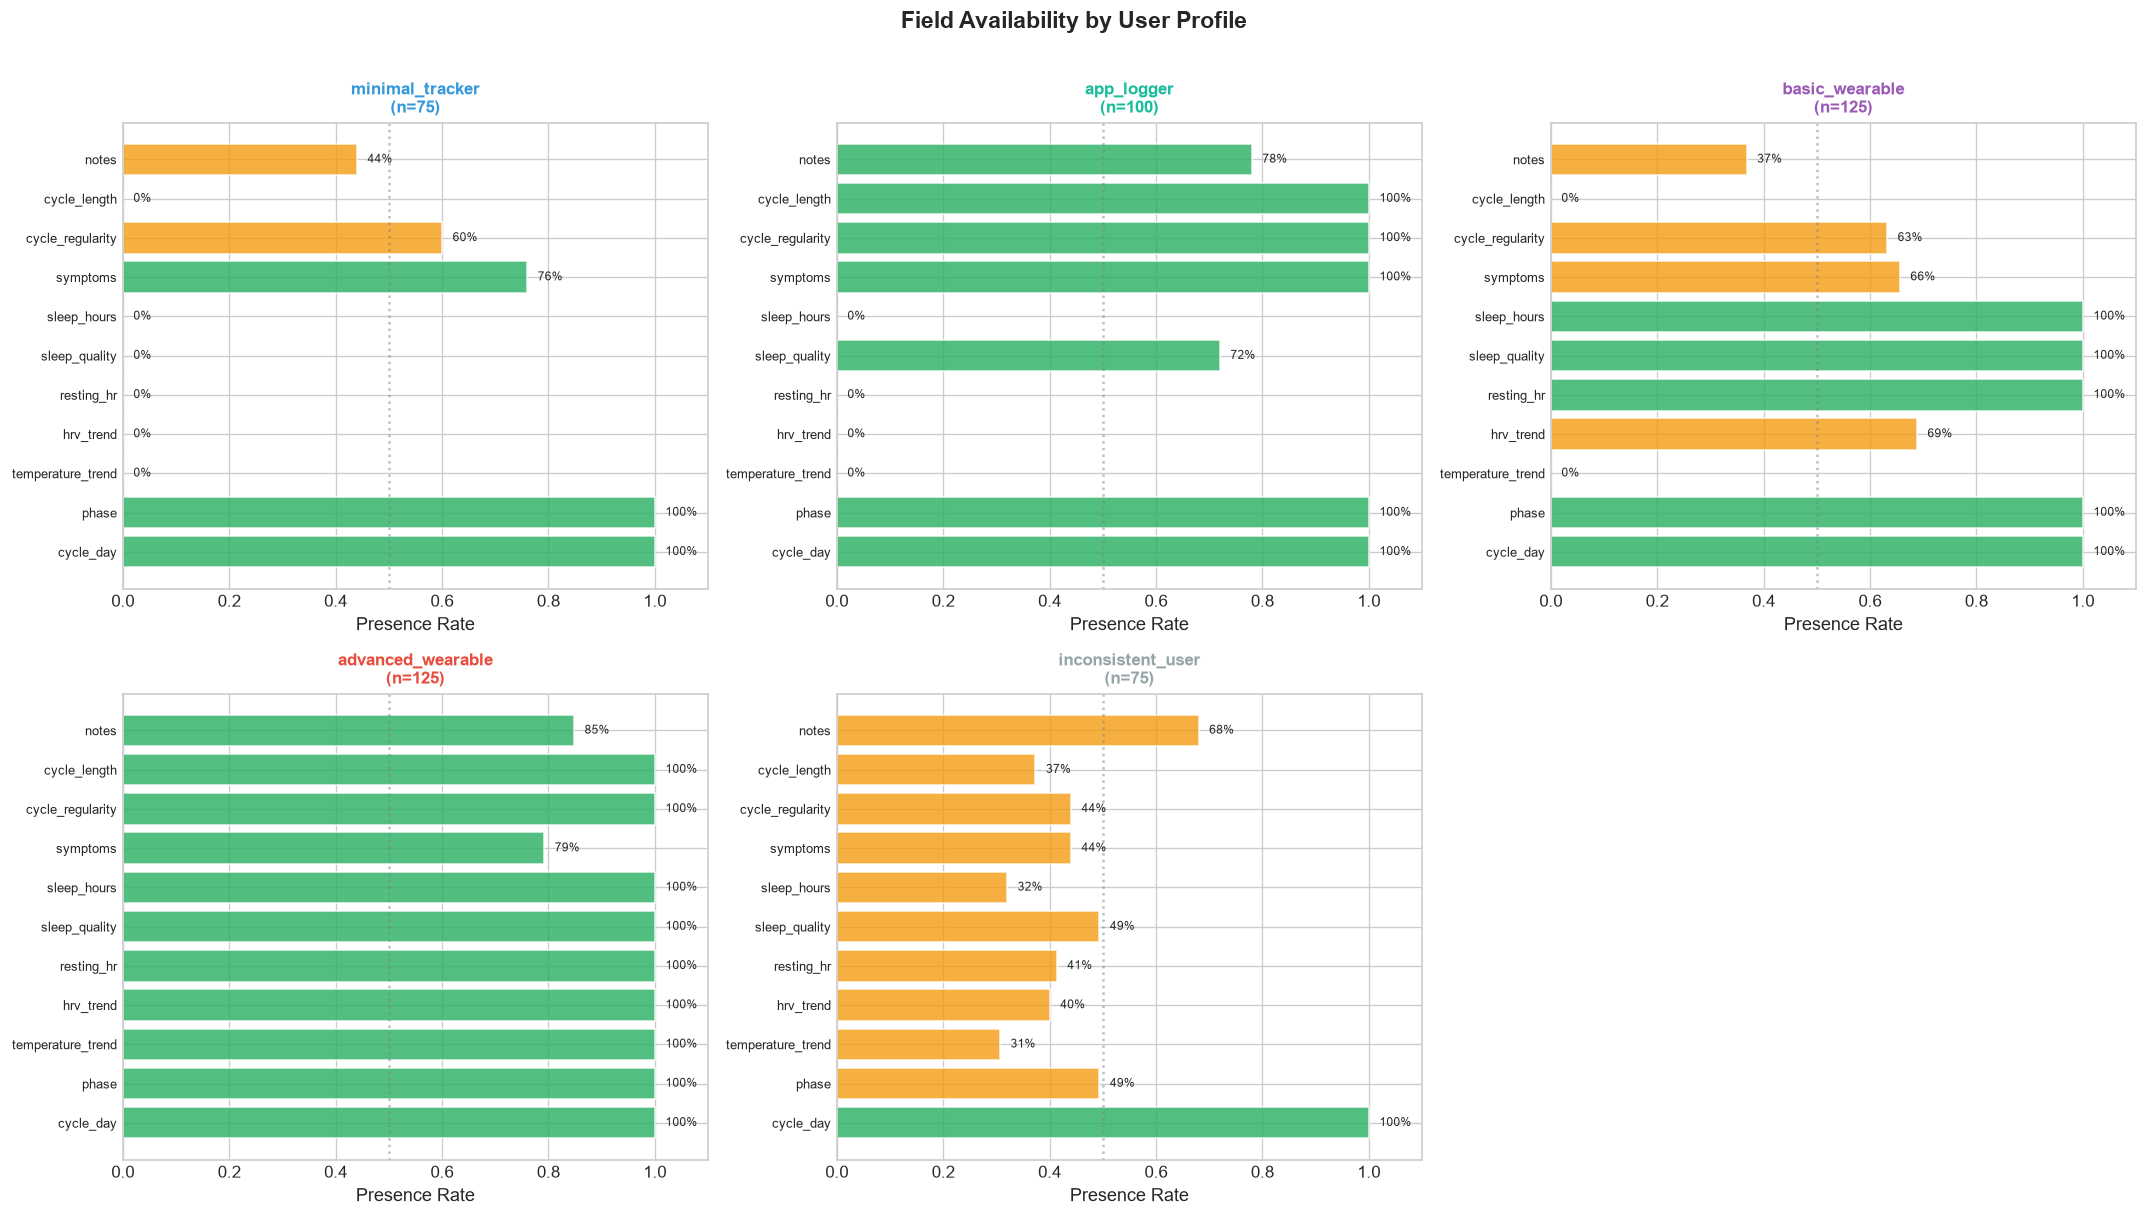

In [20]:
# =============================================================
# CELL 19: Profile Comparison - What Each User Type "Sees"
# =============================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

profiles = list(PROFILE_COLORS.keys())

for idx, profile in enumerate(profiles):
    ax = axes[idx]
    profile_df = df[df['data_profile'] == profile]

    # Field presence as radial
    field_presence = {}
    for field in field_list:
        rate = profile_df['available_fields'].apply(lambda x: field in x).mean()
        field_presence[field] = rate

    fields = list(field_presence.keys())
    rates = list(field_presence.values())

    # Horizontal bar chart
    colors = ['#27ae60' if r > 0.7 else '#f39c12' if r > 0.3 else '#e74c3c'
              for r in rates]
    ax.barh(fields, rates, color=colors, edgecolor='white', alpha=0.8)
    ax.set_xlim(0, 1.1)
    ax.axvline(0.5, color='gray', linestyle=':', alpha=0.5)
    ax.set_title(f'{profile}\n(n={len(profile_df)})',
                 fontweight='bold', fontsize=10, color=PROFILE_COLORS[profile])
    ax.set_xlabel('Presence Rate')
    ax.tick_params(axis='y', labelsize=8)

    # Add percentage text
    for i, (field, rate) in enumerate(zip(fields, rates)):
        ax.text(rate + 0.02, i, f'{rate:.0%}', va='center', fontsize=7)

# Hide extra subplot if needed
if len(profiles) < 6:
    axes[5].axis('off')

plt.suptitle('Field Availability by User Profile', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('viz_17_profile_comparison.png', bbox_inches='tight')
plt.show()

In [21]:
# =============================================================
# CELL 20: Statistical Summary Table
# =============================================================

# Create comprehensive summary table
print("=" * 70)
print("COMPREHENSIVE STATISTICAL SUMMARY")
print("=" * 70)

# Phase summary
print("\n┌─────────────────────────────────────────────────────────────────┐")
print("│                    PHASE STATISTICS                              │")
print("├─────────────────────────────────────────────────────────────────┤")
phase_summary = []
for phase in ['menstrual', 'follicular', 'ovulatory', 'luteal']:
    p_df = df[df['phase'] == phase]
    p_hr = p_df['resting_hr'].dropna()
    p_sl = p_df['sleep_hours'].dropna()
    phase_summary.append({
        'Phase': phase,
        'Count': len(p_df),
        'Pct': f"{len(p_df)/500*100:.1f}%",
        'Avg HR': f"{p_hr.mean():.1f}" if len(p_hr) > 0 else "N/A",
        'Avg Sleep': f"{p_sl.mean():.1f}" if len(p_sl) > 0 else "N/A",
        'Avg Conf': f"{p_df['confidence_score'].mean():.3f}",
        'Avg Risk': f"{p_df['risk_tier'].mean():.3f}"
    })

summary_df = pd.DataFrame(phase_summary)
print(summary_df.to_string(index=False))

# Profile summary
print("\n┌─────────────────────────────────────────────────────────────────┐")
print("│                   PROFILE STATISTICS                             │")
print("├─────────────────────────────────────────────────────────────────┤")
profile_summary = []
for profile in PROFILE_COLORS.keys():
    p_df = df[df['data_profile'] == profile]
    profile_summary.append({
        'Profile': profile,
        'Count': len(p_df),
        'Avg Fields': f"{p_df['n_available'].mean():.1f}",
        'Avg Conf': f"{p_df['confidence_score'].mean():.3f}",
        'Notes Rate': f"{p_df['notes'].notna().mean():.1%}"
    })

print(pd.DataFrame(profile_summary).to_string(index=False))

# Difficulty summary
print("\n┌─────────────────────────────────────────────────────────────────┐")
print("│                  DIFFICULTY STATISTICS                            │")
print("├─────────────────────────────────────────────────────────────────┤")
diff_summary = []
for diff in DIFFICULTIES:
    d_df = df[df['difficulty'] == diff]
    diff_summary.append({
        'Difficulty': diff,
        'Count': len(d_df),
        'Avg Conf': f"{d_df['confidence_score'].mean():.3f}",
        'Avg Risk': f"{d_df['risk_tier'].mean():.3f}",
        'Conf Range': f"[{d_df['confidence_score'].min():.2f}-{d_df['confidence_score'].max():.2f}]",
        'Risk Range': f"[{d_df['risk_tier'].min():.2f}-{d_df['risk_tier'].max():.2f}]"
    })

print(pd.DataFrame(diff_summary).to_string(index=False))
print("\n└─────────────────────────────────────────────────────────────────┘")

COMPREHENSIVE STATISTICAL SUMMARY

┌─────────────────────────────────────────────────────────────────┐
│                    PHASE STATISTICS                              │
├─────────────────────────────────────────────────────────────────┤
     Phase  Count   Pct Avg HR Avg Sleep Avg Conf Avg Risk
 menstrual     70 14.0%   66.2       6.8    0.690    0.274
follicular    135 27.0%   64.5       7.2    0.658    0.329
 ovulatory     73 14.6%   69.1       6.7    0.641    0.312
    luteal    184 36.8%   72.1       6.2    0.679    0.282

┌─────────────────────────────────────────────────────────────────┐
│                   PROFILE STATISTICS                             │
├─────────────────────────────────────────────────────────────────┤
          Profile  Count Avg Fields Avg Conf Notes Rate
  minimal_tracker     75        3.8    0.602      44.0%
       app_logger    100        6.5    0.657      78.0%
   basic_wearable    125        7.3    0.677      36.8%
advanced_wearable    125       10.6

NameError: name 'DIFFICULTIES' is not defined

In [22]:
# =============================================================
# CELL 21: Export Visualization Summary & Index
# =============================================================

viz_files = [
    ("viz_01_distributions_overview.png", "Phase, Profile, and Difficulty distributions"),
    ("viz_02_phase_by_category.png", "Phase distribution by difficulty and profile"),
    ("viz_03_resting_hr_analysis.png", "Resting heart rate analysis across dimensions"),
    ("viz_04_sleep_analysis.png", "Sleep hours and quality analysis"),
    ("viz_05_trends_analysis.png", "Temperature and HRV trend analysis"),
    ("viz_06_confidence_risk.png", "Confidence score and risk tier analysis"),
    ("viz_07_symptoms_analysis.png", "Symptom frequency and distribution"),
    ("viz_08_data_completeness.png", "Data completeness and field presence"),
    ("viz_09_cycle_analysis.png", "Cycle day and cycle length analysis"),
    ("viz_10_conflict_analysis.png", "Conflicting samples analysis"),
    ("viz_11_elevated_risk.png", "Elevated risk samples analysis"),
    ("viz_12_correlation_multivariate.png", "Correlation matrix and multivariate"),
    ("viz_13_notes_analysis.png", "Notes/free-text field analysis"),
    ("viz_14_dashboard_summary.png", "Comprehensive dashboard summary"),
    ("viz_15_radar_profiles.png", "Phase physiological profiles (radar)"),
    ("viz_16_temporal_progression.png", "Temporal progression across cycle days"),
    ("viz_17_profile_comparison.png", "Field availability by user profile"),
]

print("=" * 60)
print("GENERATED VISUALIZATIONS INDEX")
print("=" * 60)
print(f"\n{'#':<4} {'Filename':<45} {'Description'}")
print("-" * 100)
for i, (fname, desc) in enumerate(viz_files, 1):
    print(f"{i:<4} {fname:<45} {desc}")

print(f"\n{'=' * 60}")
print(f"Total visualizations generated: {len(viz_files)}")
print(f"Dataset file: menstrual_health_dataset.json")
print(f"Total samples: 500")
print(f"{'=' * 60}")
print("\n✓ All visualizations complete!")

GENERATED VISUALIZATIONS INDEX

#    Filename                                      Description
----------------------------------------------------------------------------------------------------
1    viz_01_distributions_overview.png             Phase, Profile, and Difficulty distributions
2    viz_02_phase_by_category.png                  Phase distribution by difficulty and profile
3    viz_03_resting_hr_analysis.png                Resting heart rate analysis across dimensions
4    viz_04_sleep_analysis.png                     Sleep hours and quality analysis
5    viz_05_trends_analysis.png                    Temperature and HRV trend analysis
6    viz_06_confidence_risk.png                    Confidence score and risk tier analysis
7    viz_07_symptoms_analysis.png                  Symptom frequency and distribution
8    viz_08_data_completeness.png                  Data completeness and field presence
9    viz_09_cycle_analysis.png                     Cycle day and cycle length an

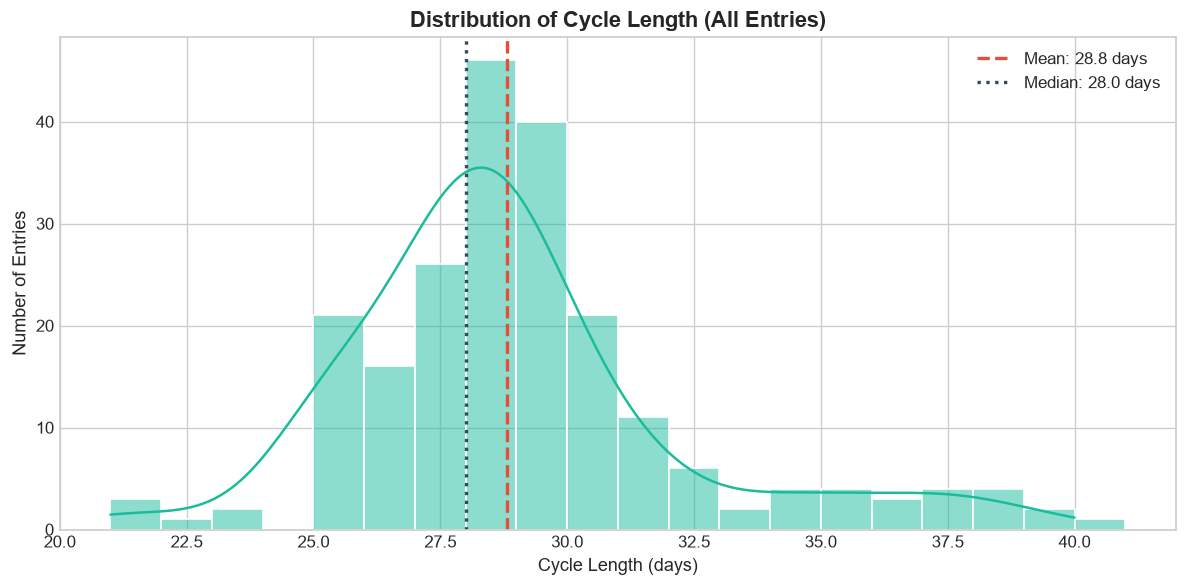

Plotted 217 entries with cycle_length values.


: 

In [ ]:
# Cycle Length Distribution (all entries with available cycle_length)
if 'df' in globals():
    df_cycle = df.copy()
else:
    with open('menstrual_health_dataset.json', 'r', encoding='utf-8') as f:
        dataset = json.load(f)
    df_cycle = pd.DataFrame(dataset['samples'])

cycle_lengths = pd.to_numeric(df_cycle['cycle_length'], errors='coerce').dropna()

if cycle_lengths.empty:
    print('No cycle_length values available to plot.')
else:
    plt.figure(figsize=(10, 5))
    bins = range(int(cycle_lengths.min()), int(cycle_lengths.max()) + 2)
    sns.histplot(cycle_lengths, bins=bins, kde=True, color='#1abc9c', edgecolor='white')
    
    mean_len = cycle_lengths.mean()
    median_len = cycle_lengths.median()
    plt.axvline(mean_len, color='#e74c3c', linestyle='--', linewidth=2, label=f'Mean: {mean_len:.1f} days')
    plt.axvline(median_len, color='#34495e', linestyle=':', linewidth=2, label=f'Median: {median_len:.1f} days')
    
    plt.title('Distribution of Cycle Length (All Entries)', fontweight='bold')
    plt.xlabel('Cycle Length (days)')
    plt.ylabel('Number of Entries')
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f'Plotted {len(cycle_lengths)} entries with cycle_length values.')